# **Emotion Classification using GloVe Embeddings and LSTM**

### Emotion Distribution

| Label | Emotion  | Count |
|------:|----------|------:|
| 0     | Sadness  | 4,666 |
| 1     | Joy      | 5,362 |
| 2     | Love     | 1,304 |
| 3     | Anger    | 2,159 |
| 4     | Fear     | 1,937 |
| 5     | Surprise | 572   |

## **Importing Libraries**

In [1]:
!pip install tensorflow pandas numpy scikit-learn matplotlib seaborn nltk wordcloud gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 30.9 MB/s eta 0:00:00


In [2]:
import os
import pickle
import re
import urllib.request
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

## **Loading Dataset**

In [3]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/training.csv")

In [4]:
df

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3
...,...,...
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,1
15998,i feel like this was such a rude comment and i...,3


In [5]:
df.shape

(16000, 2)

## **Understanding Dataset**

In [6]:
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

In [7]:
df.sample(5)

,text,label
11445,i feel them and im loving it,2
1120,im not sure i relish the feeling of squelching mud between my toes when its contents are uncertain,4
10372,im feeling hopeful that the last piece in the lighting jigsaw may be finally complete,1
12451,i want to write about this because i left campus feeling truly thankful to wesleyan for putting on the kind of event i never dreamed i d be able to attend after just a fairly short car ride,1
10301,im gonna end up pressuring myself and feeling really disappointed when i get to doing the actual thing and its on tuesday and i really should study but i cant jhbdjhdfbjdfhbfd or maybe when i get off this comp ill go start typing stuff up,0


In [8]:
df['label'].unique()

array([0, 3, 2, 5, 4, 1])

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    16000 non-null  object
 1   label   16000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 250.1+ KB


In [10]:
df.shape

(16000, 2)

In [11]:
df.describe()

,label
count,16000.000000
mean,1.565937
std,1.501430
min,0.000000
25%,0.000000
50%,1.000000
75%,3.000000
max,5.000000


In [12]:
df.describe(include="object")

,text
count,16000
unique,15969
top,im still not sure why reilly feels the need to be so weird
freq,2


In [13]:
df.describe(include="all")

,text,label
count,16000,16000.000000
unique,15969,NaN
top,im still not sure why reilly feels the need to be so weird,NaN
freq,2,NaN
mean,NaN,1.565937
std,NaN,1.501430
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,1.000000
75%,NaN,3.000000


In [14]:
df.isnull().sum()

,0
text,0
label,0


In [15]:
df.duplicated().sum()

np.int64(1)

In [16]:
df[df.duplicated(keep=False)]

,text,label
4975,i feel more adventurous willing to take risks img src http cdn,1
13846,i feel more adventurous willing to take risks img src http cdn,1


In [17]:
df.drop_duplicates(inplace=True)

In [18]:
# Find texts that have different emotion labels
conflicting_texts = (
    df.groupby("text")["label"]
      .nunique()
      .loc[lambda x: x > 1]
)

# Display all rows for those texts
df[df["text"].isin(conflicting_texts.index)].sort_values("text")

,text,label
3508,i am not amazing or great at photography but i feel passionate about it,1
8246,i am not amazing or great at photography but i feel passionate about it,2
15705,i began to feel accepted by gaia on her own terms,1
5277,i began to feel accepted by gaia on her own terms,2
15572,i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,3
8804,i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,4
11013,i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,2
12892,i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,1
13653,i could feel myself hit this strange foggy wall,4
14314,i could feel myself hit this strange foggy wall,5


In [19]:
df["text"].duplicated().sum()

np.int64(30)

In [20]:
duplicate_counts = df["text"].value_counts()
duplicate_counts = duplicate_counts[duplicate_counts > 1]

display(duplicate_counts)

,count
text,
i still feel completely accepted,2
i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,2
i began to feel accepted by gaia on her own terms,2
im still not sure why reilly feels the need to be so weird,2
i feel pretty weird blogging about deodorant but im a bit of a deodorant snob and find it really hard to find a good one,2
i still feel a craving for sweet food,2
i feel kind of strange,2
i write these words i feel sweet baby kicks from within and my memory is refreshed i would do anything for this boy,2
i tend to stop breathing when i m feeling stressed,2


In [21]:
# Remove duplicate texts
df = df.drop_duplicates(subset=["text"], keep="first")

# Reset index
df = df.reset_index(drop=True)

print("Duplicate texts:", df["text"].duplicated().sum())
print("New dataset shape:", df.shape)

Duplicate texts: 0
New dataset shape: (15969, 2)


In [22]:
df.shape

(15969, 2)

In [23]:
df.index = range(len(df))
df['text'].apply(lambda x: len(x.split(' '))).sum()

np.int64(306153)

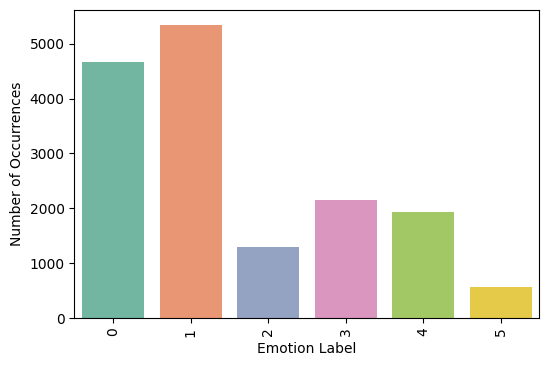

In [24]:
plt.figure(figsize=(6,4))
sns.countplot(x="label",data=df,palette='Set2')
plt.ylabel('Number of Occurrences')
plt.xlabel('Emotion Label')
plt.xticks(rotation=90)
plt.show()

In [25]:
LABEL_NAMES = ["sadness", "joy", "love", "anger", "fear", "surprise"]

# The column 'label' was renamed to 'emotion' in a later cell.
# If 'emotion' is still numeric, we map it to string labels:
if "emotion" in df.columns and df["emotion"].dtype in ["int64", "int32"]:
    df["emotion"] = df["emotion"].apply(lambda x: LABEL_NAMES[x])
elif "label" in df.columns:
    df["emotion"] = df["label"].apply(lambda x: LABEL_NAMES[x])
    df.drop(columns=["label"], inplace=True)

In [26]:
df["word_count"] = df["text"].apply(lambda x: len(x.split(" ")))
print("Total words in the corpus:", df["word_count"].sum())
df["word_count"].describe()

Total words in the corpus: 306153


,word_count
count,15969.000000
mean,19.171708
std,10.990862
min,2.000000
25%,11.000000
50%,17.000000
75%,25.000000
max,66.000000


In [27]:
df.rename(columns={'label': 'emotion'}, inplace=True)
display(df.head())

,text,emotion,word_count
0,i didnt feel humiliated,sadness,4
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness,21
2,im grabbing a minute to post i feel greedy wrong,anger,10
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,love,18
4,i am feeling grouchy,anger,4


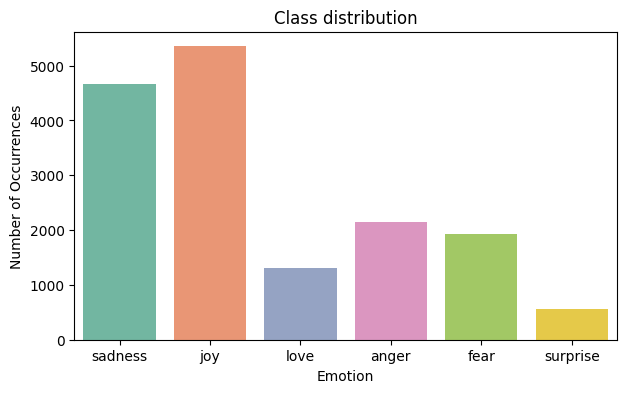

In [28]:
plt.figure(figsize=(7, 4))
sns.countplot(x="emotion", data=df, order=LABEL_NAMES, palette="Set2")
plt.ylabel("Number of Occurrences")
plt.xlabel("Emotion")
plt.title("Class distribution")
plt.show()

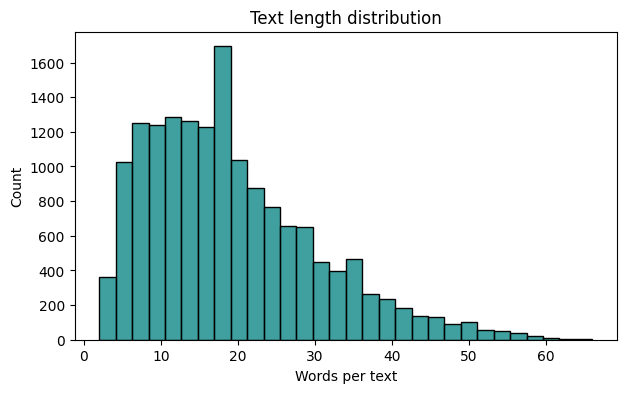

In [29]:
plt.figure(figsize=(7, 4))
sns.histplot(df["word_count"], bins=30, color="teal")
plt.xlabel("Words per text")
plt.title("Text length distribution")
plt.show()

# **Data Cleaning**

We create two versions of the text:
* `cleaned_text` (stop-words kept) is the input to the **LSTM**. Words such as *not*, *i* and *feel* carry emotional meaning and word order matters, so nothing more is removed.
* `tokens` (stop-words removed and lemmatized) is used only for **visualization**, to see the content words.

## **1. Removing unnecessary/special characters**
Remove leftover HTML/link fragments (for example `a href http`, `img src`), then everything that is not a letter or whitespace.

In [30]:
def remove_unnecessary_characters(text):
    text = re.sub(r"\b(?:a href|img src|href|src|https?|www)\b", " ", text, flags=re.I)  # HTML/link remnants
    text = re.sub(r"[^a-zA-Z\s]", "", text)     # keep only letters and whitespace (didn't -> didnt)
    text = re.sub(r"\s+", " ", text).strip()     # collapse whitespace
    return text

df["cleaned_text"] = df["text"].apply(remove_unnecessary_characters)

In [31]:
df.head(5)

,text,emotion,word_count,cleaned_text
0,i didnt feel humiliated,sadness,4,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness,21,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
2,im grabbing a minute to post i feel greedy wrong,anger,10,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,love,18,i am ever feeling nostalgic about the fireplace i will know that it is still on the property
4,i am feeling grouchy,anger,4,i am feeling grouchy


## **2. Lowercasing each character in the text**
Convert all text to lowercase to ensure consistency

In [32]:
def to_lowercase(text):
    return text.lower()

df["cleaned_text"] = df["cleaned_text"].apply(to_lowercase)
df.head()

,text,emotion,word_count,cleaned_text
0,i didnt feel humiliated,sadness,4,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness,21,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
2,im grabbing a minute to post i feel greedy wrong,anger,10,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,love,18,i am ever feeling nostalgic about the fireplace i will know that it is still on the property
4,i am feeling grouchy,anger,4,i am feeling grouchy


## **3. Tokenization**
Split sentences into individual words (tokens)

In [33]:
def tokenize(text):
    return text.split()  # split by space to get individual words

df["tokens"] = df["cleaned_text"].apply(tokenize)
df.head(2)

,text,emotion,word_count,cleaned_text,tokens
0,i didnt feel humiliated,sadness,4,i didnt feel humiliated,"[i, didnt, feel, humiliated]"
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness,21,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,"[i, can, go, from, feeling, so, hopeless, to, so, damned, hopeful, just, from, being, around, someone, who, cares, and, is, awake]"


## **4. Removing Stopwords (for visualization only)**
Remove common stopwords like "and", "the" etc. to focus on meaningful words.

In [34]:
import nltk
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [35]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

df["tokens"] = df["tokens"].apply(remove_stopwords)
df.head(2)

,text,emotion,word_count,cleaned_text,tokens
0,i didnt feel humiliated,sadness,4,i didnt feel humiliated,"[didnt, feel, humiliated]"
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness,21,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,"[go, feeling, hopeless, damned, hopeful, around, someone, cares, awake]"


## **5. Lemmatization (for visualization only)**
Convert words to their lemma or dictionary base forms.

In [36]:
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [37]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def lemmatize(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]

df["tokens"] = df["tokens"].apply(lemmatize)
df.head(2)

,text,emotion,word_count,cleaned_text,tokens
0,i didnt feel humiliated,sadness,4,i didnt feel humiliated,"[didnt, feel, humiliated]"
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness,21,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,"[go, feeling, hopeless, damned, hopeful, around, someone, care, awake]"


## **6. Handling Null / Empty Values (If Any)**

In [38]:
df.isnull().sum()

,0
text,0
emotion,0
word_count,0
cleaned_text,0
tokens,0


# **Data Visualization**

## **1. Word Cloud**
Visualize the most frequent words in each emotion category

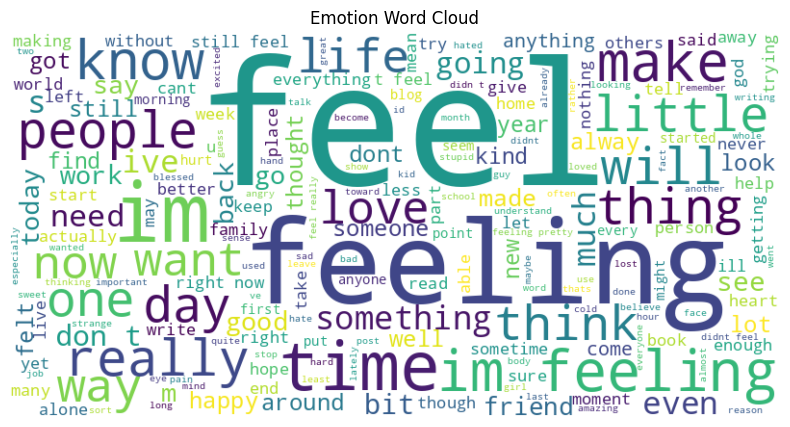

In [39]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def generate_wordcloud(df):
    # Generate text from the 'cleaned_text' column
    all_text = " ".join(df["cleaned_text"])

    # Create the word cloud
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(all_text)

    # Plot the word cloud
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Emotion Word Cloud")
    plt.show()

generate_wordcloud(df)

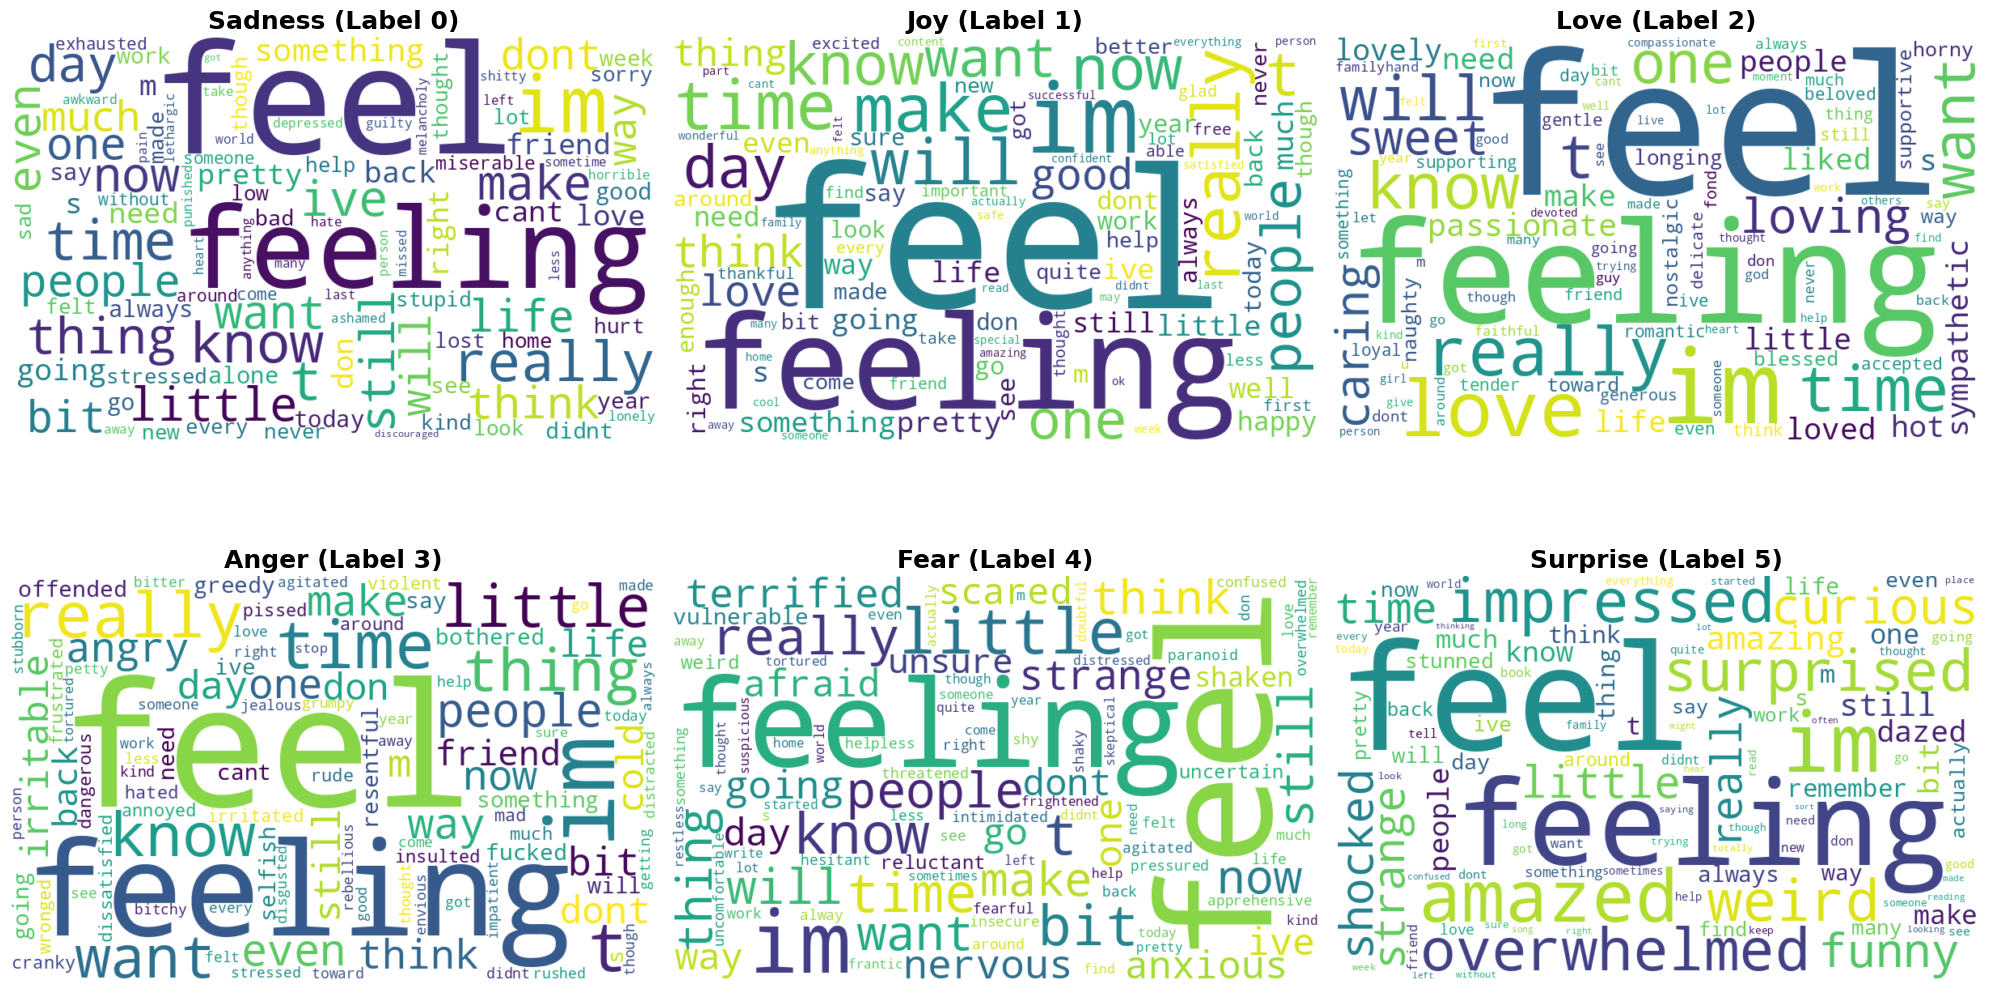

In [81]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Emotion labels
LABEL_NAMES = ["Sadness", "Joy", "Love", "Anger", "Fear", "Surprise"]

# Create 2 rows % 3 columns
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Generate word cloud for each emotion
for label, emotion, ax in zip(range(6), LABEL_NAMES, axes.ravel()):

    # Get all text for the current emotion (lowercasing to match "sadness", "joy", etc.)
    emotion_text = " ".join(
        df[df["emotion"] == emotion.lower()]["cleaned_text"].dropna().astype(str)
    )

    # Generate word cloud
    wordcloud = WordCloud(
        width=800,
        height=500,
        background_color="white",
        max_words=100,
        min_font_size=10,
        collocations=False
    ).generate(emotion_text)

    # Display word cloud
    ax.imshow(wordcloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(
        f"{emotion} (Label {label})",
        fontsize=18,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## **2. Word Frequency**

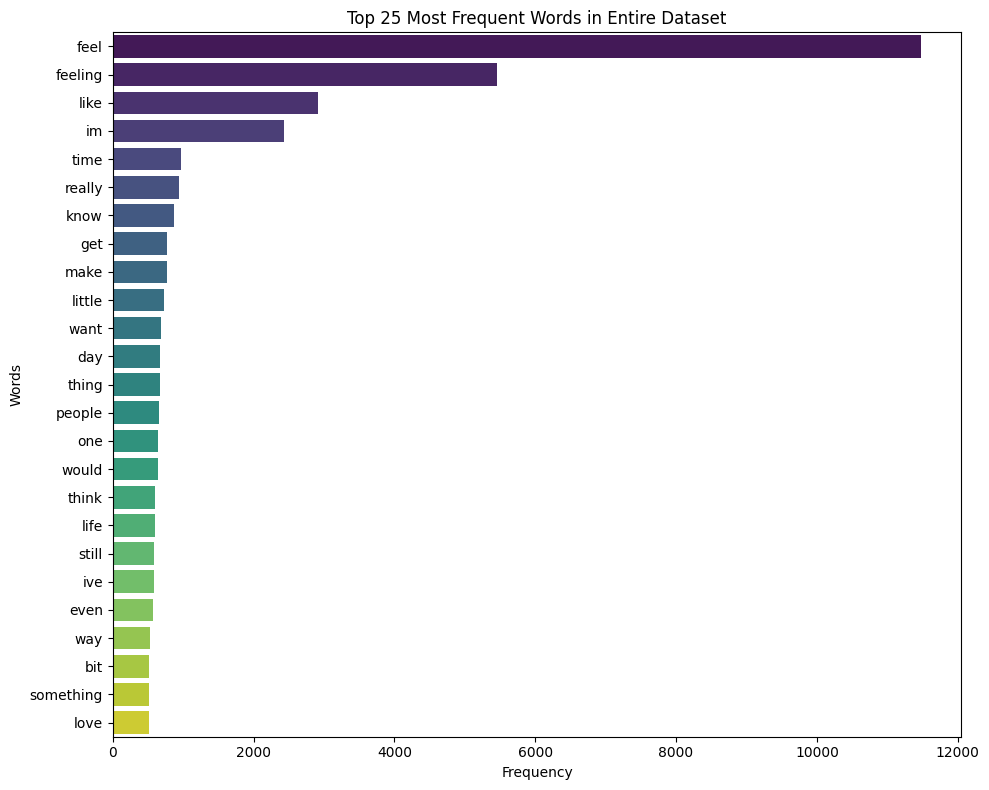

In [40]:
from collections import Counter

def plot_word_frequency(df, num_words=50):
    all_words = [word for tokens in df["tokens"] for word in tokens]   # flatten the list
    common_words = Counter(all_words).most_common(num_words)
    words, counts = zip(*common_words)

    plt.figure(figsize=(10, 8))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title(f"Top {num_words} Most Frequent Words in Entire Dataset")
    plt.xlabel("Frequency")
    plt.ylabel("Words")
    plt.tight_layout()
    plt.show()

plot_word_frequency(df, 25)

In [41]:
def plot_word_frequency_by_emotion(df, emotion, num_words=25):
    emotion_tokens = df[df["emotion"] == emotion]["tokens"]
    all_words = [word for tokens in emotion_tokens for word in tokens]
    common_words = Counter(all_words).most_common(num_words)
    words, counts = zip(*common_words)

    plt.figure(figsize=(10, 8))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title(f"Top {num_words} Most Frequent Words for {emotion.capitalize()}")
    plt.xlabel("Frequency")
    plt.ylabel("Words")
    plt.tight_layout()
    plt.show()

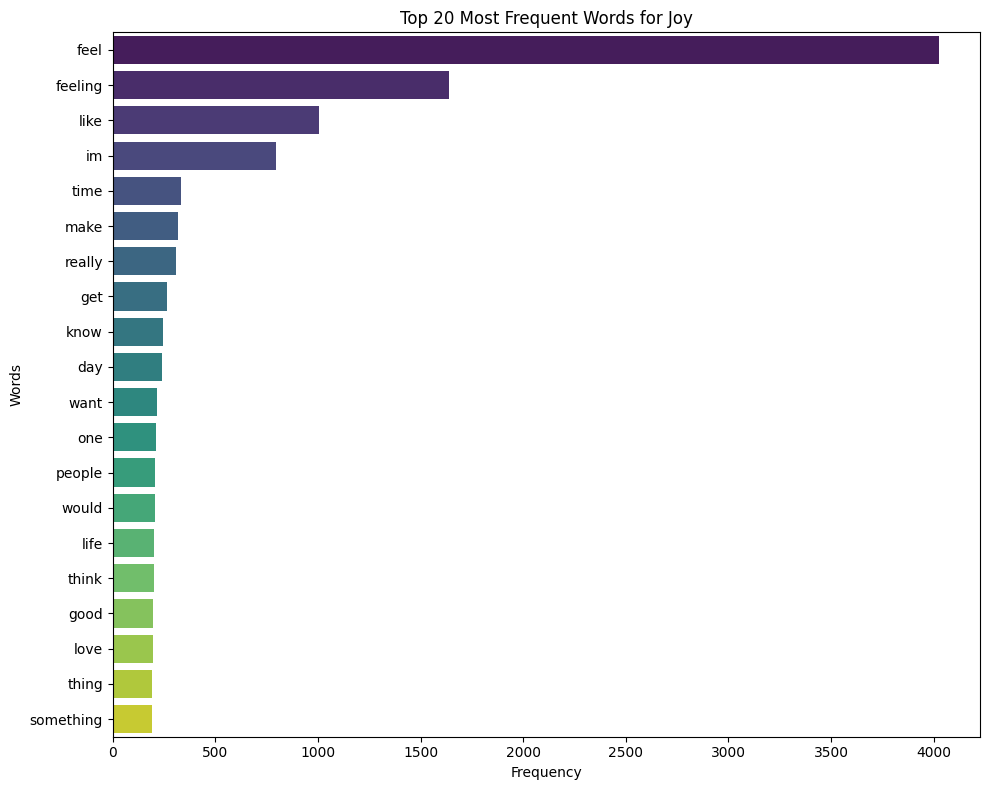

In [42]:
plot_word_frequency_by_emotion(df, "joy", 20)

In [83]:
from collections import Counter

# Get the tokens for the joy emotion
joy_tokens = df[df["emotion"] == "joy"]["tokens"]
all_joy_words = [word for tokens in joy_tokens for word in tokens]

# Define joy_top_words (for example, the top 20 most common words)
joy_top_words = Counter(all_joy_words).most_common(20)

# Now extract the words from the tuple list
joy_words = [word for word, count in joy_top_words]

print(joy_words)

['feel', 'feeling', 'like', 'im', 'time', 'make', 'really', 'get', 'know', 'day', 'want', 'one', 'people', 'would', 'life', 'think', 'good', 'love', 'thing', 'something']


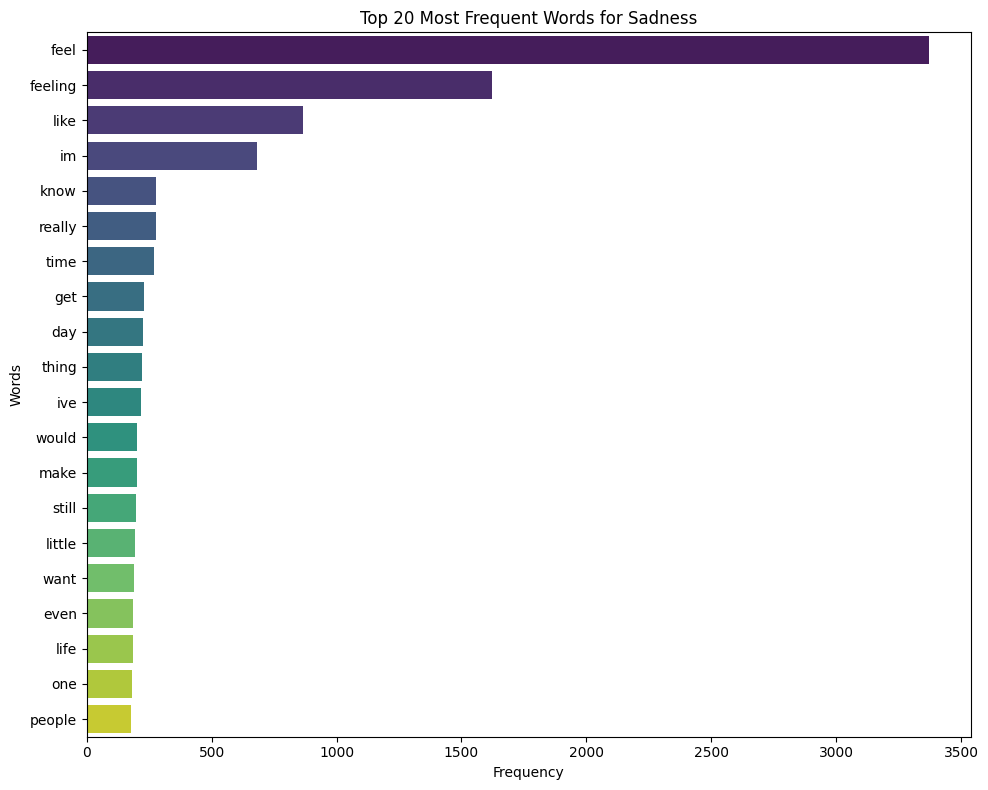

In [43]:
plot_word_frequency_by_emotion(df, "sadness", 20)

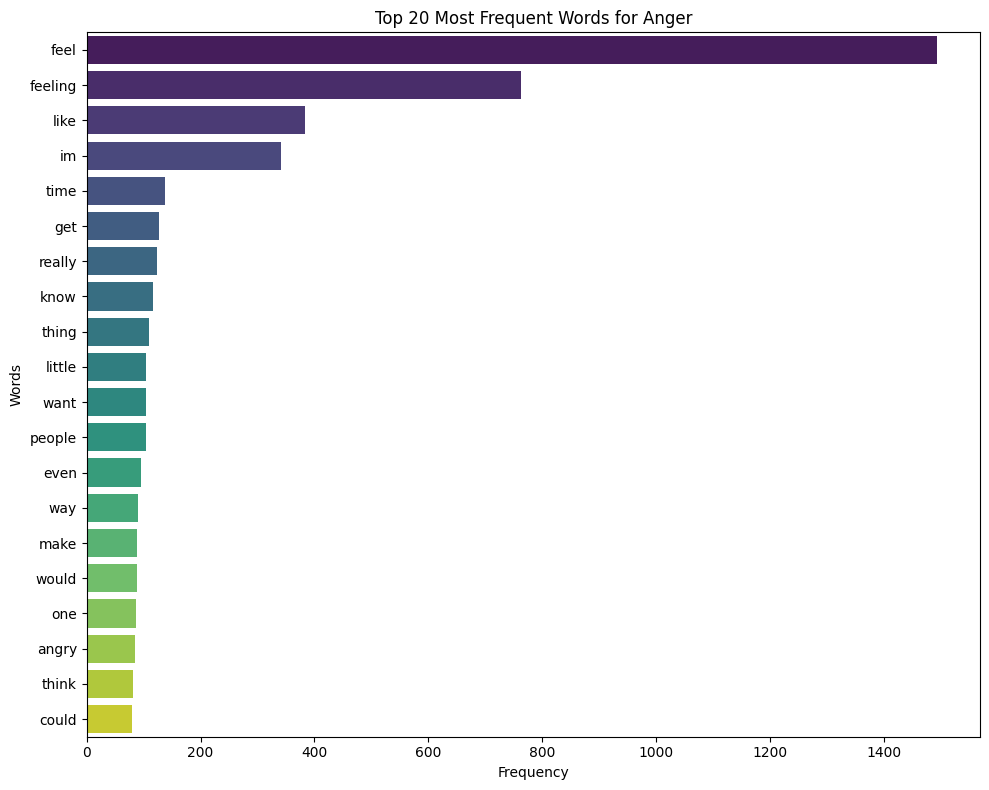

In [44]:
plot_word_frequency_by_emotion(df, "anger", 20)

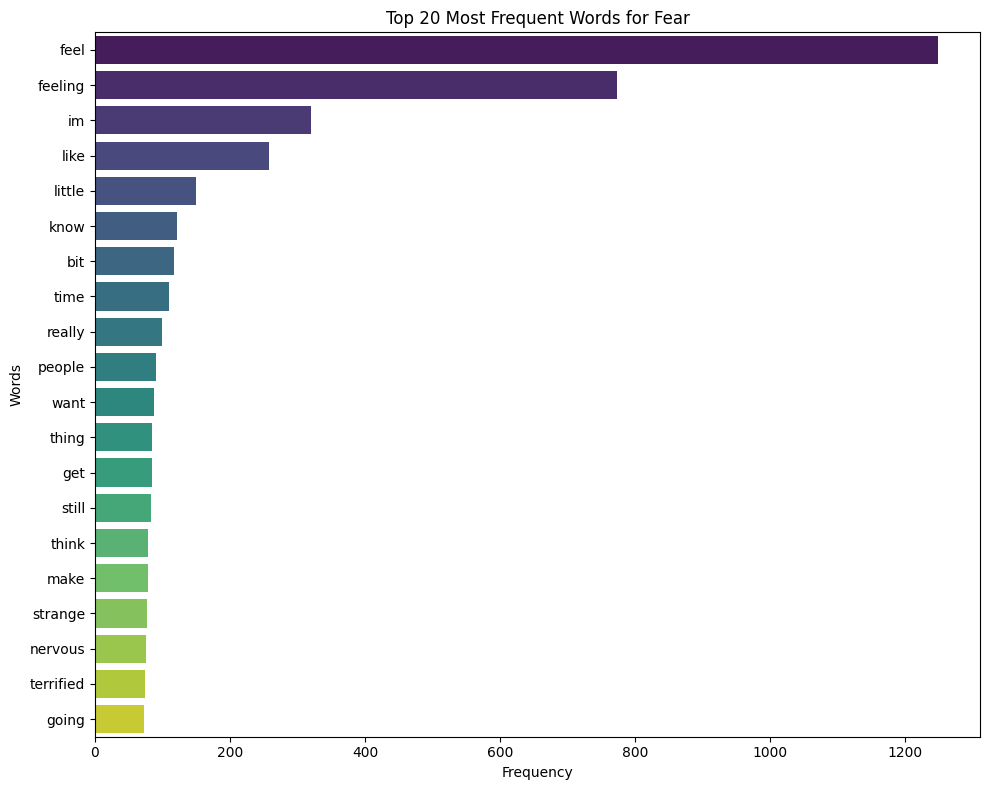

In [45]:
plot_word_frequency_by_emotion(df, "fear", 20)

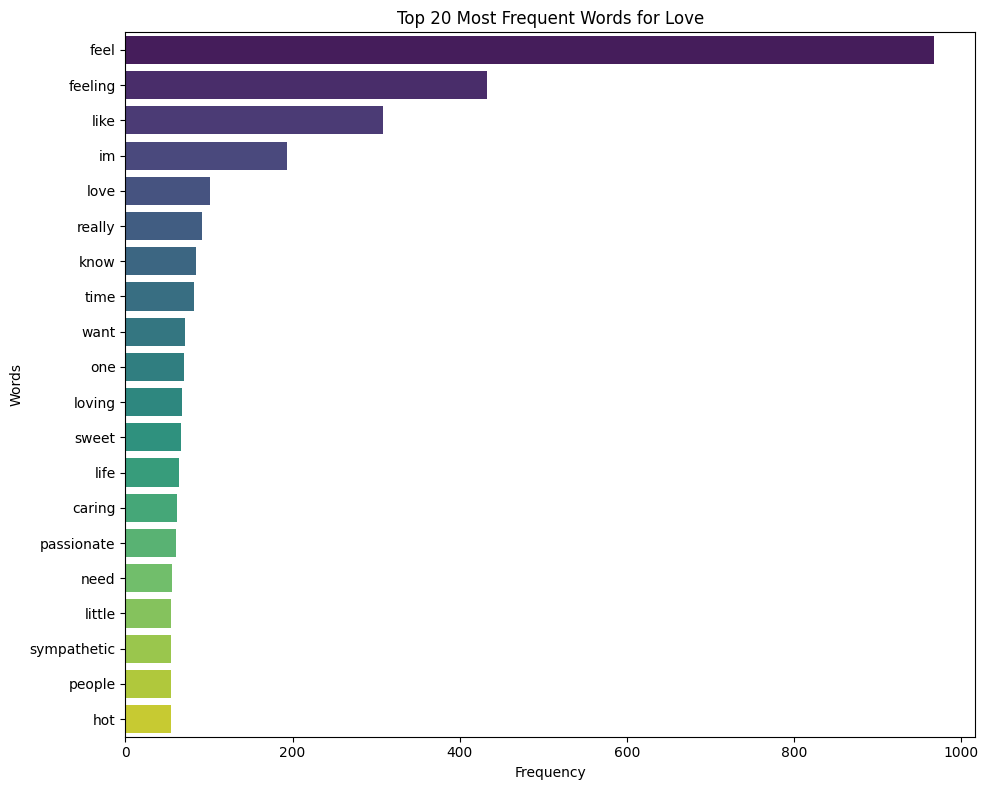

In [46]:
plot_word_frequency_by_emotion(df, "love", 20)

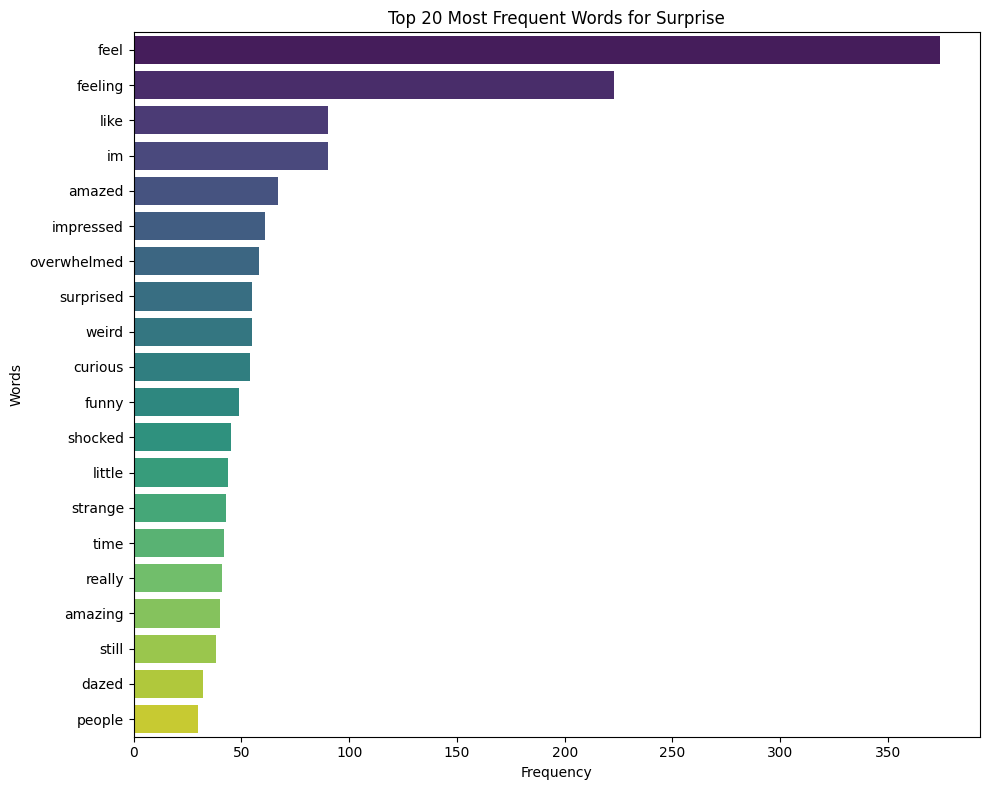

In [47]:
plot_word_frequency_by_emotion(df, "surprise", 20)

In [84]:
from collections import Counter

# =========================
# 1. SADNESS
# =========================

sadness_tokens = df[df["emotion"] == "sadness"]["tokens"]
all_sadness_words = [word for tokens in sadness_tokens for word in tokens]

sadness_top_words = Counter(all_sadness_words).most_common(20)
sadness_words = [word for word, count in sadness_top_words]

print("Sadness:")
print(sadness_words)


# =========================
# 2. JOY
# =========================

joy_tokens = df[df["emotion"] == "joy"]["tokens"]
all_joy_words = [word for tokens in joy_tokens for word in tokens]

joy_top_words = Counter(all_joy_words).most_common(20)
joy_words = [word for word, count in joy_top_words]

print("\nJoy:")
print(joy_words)


# =========================
# 3. LOVE
# =========================

love_tokens = df[df["emotion"] == "love"]["tokens"]
all_love_words = [word for tokens in love_tokens for word in tokens]

love_top_words = Counter(all_love_words).most_common(20)
love_words = [word for word, count in love_top_words]

print("\nLove:")
print(love_words)


# =========================
# 4. ANGER
# =========================

anger_tokens = df[df["emotion"] == "anger"]["tokens"]
all_anger_words = [word for tokens in anger_tokens for word in tokens]

anger_top_words = Counter(all_anger_words).most_common(20)
anger_words = [word for word, count in anger_top_words]

print("\nAnger:")
print(anger_words)


# =========================
# 5. FEAR
# =========================

fear_tokens = df[df["emotion"] == "fear"]["tokens"]
all_fear_words = [word for tokens in fear_tokens for word in tokens]

fear_top_words = Counter(all_fear_words).most_common(20)
fear_words = [word for word, count in fear_top_words]

print("\nFear:")
print(fear_words)


# =========================
# 6. SURPRISE
# =========================

surprise_tokens = df[df["emotion"] == "surprise"]["tokens"]
all_surprise_words = [word for tokens in surprise_tokens for word in tokens]

surprise_top_words = Counter(all_surprise_words).most_common(20)
surprise_words = [word for word, count in surprise_top_words]

print("\nSurprise:")
print(surprise_words)

Sadness:
['feel', 'feeling', 'like', 'im', 'know', 'really', 'time', 'get', 'day', 'thing', 'ive', 'would', 'make', 'still', 'little', 'want', 'even', 'life', 'one', 'people']

Joy:
['feel', 'feeling', 'like', 'im', 'time', 'make', 'really', 'get', 'know', 'day', 'want', 'one', 'people', 'would', 'life', 'think', 'good', 'love', 'thing', 'something']

Love:
['feel', 'feeling', 'like', 'im', 'love', 'really', 'know', 'time', 'want', 'one', 'loving', 'sweet', 'life', 'caring', 'passionate', 'need', 'little', 'sympathetic', 'people', 'hot']

Anger:
['feel', 'feeling', 'like', 'im', 'time', 'get', 'really', 'know', 'thing', 'little', 'want', 'people', 'even', 'way', 'make', 'would', 'one', 'angry', 'think', 'could']

Fear:
['feel', 'feeling', 'im', 'like', 'little', 'know', 'bit', 'time', 'really', 'people', 'want', 'thing', 'get', 'still', 'think', 'make', 'strange', 'nervous', 'terrified', 'going']

Surprise:
['feel', 'feeling', 'like', 'im', 'amazed', 'impressed', 'overwhelmed', 'surpri

### **Observation (word frequency):**
1. `feel` and `feeling` are among the most frequent words in **every** emotion, because almost every text follows the pattern "i feel ...". They do not help to separate the classes.
2. The words that tell the classes apart are the ones after "feel", for example `love` for the love class, and words such as `amazed` and `impressed` for surprise.
3. Since the emotion is carried by the words around "feel", a sequence model like an LSTM is a good fit.

## **3. Bi-grams Visualization**
This will visualize the most frequent pairs of words (bigrams)

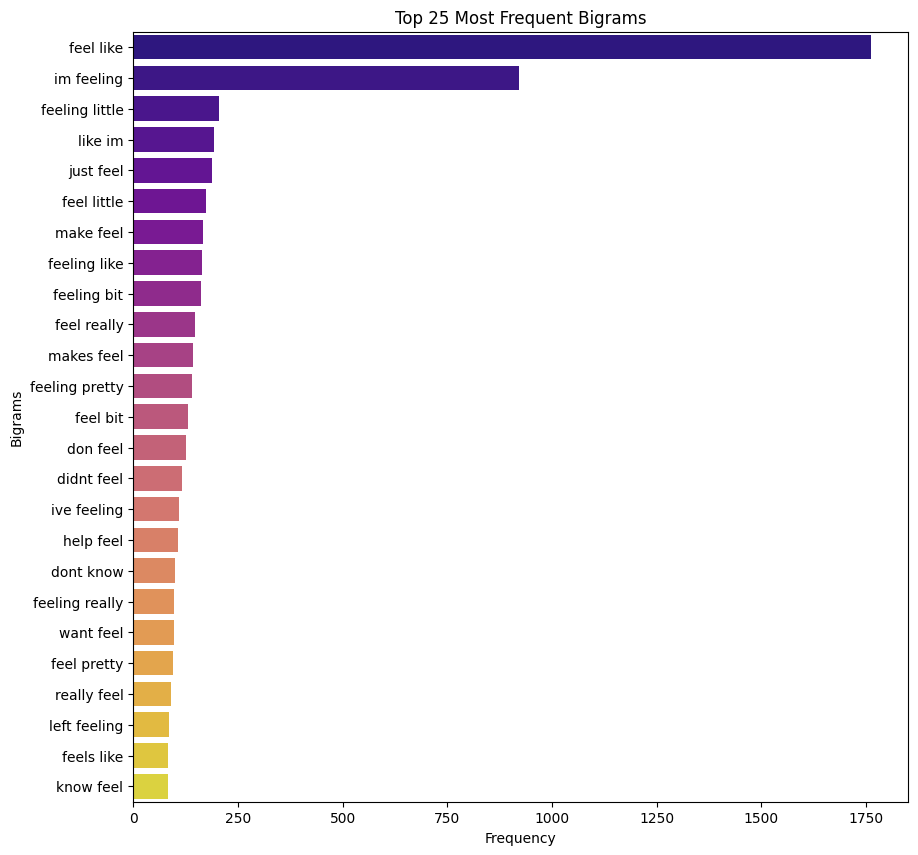

In [48]:
from sklearn.feature_extraction.text import CountVectorizer

def plot_top_ngrams(corpus, ngram_range=(2, 2), num_ngrams=25, name="Bigrams", palette="plasma"):
    vectorizer = CountVectorizer(ngram_range=ngram_range, stop_words="english")
    X = vectorizer.fit_transform(corpus)
    ngram_counts = X.sum(axis=0).A1
    ngram_names = vectorizer.get_feature_names_out()

    ngrams_df = pd.DataFrame({"ngram": ngram_names, "count": ngram_counts})
    top_ngrams = ngrams_df.nlargest(num_ngrams, "count")

    plt.figure(figsize=(10, 10))
    sns.barplot(x="count", y="ngram", data=top_ngrams, palette=palette)
    plt.title(f"Top {num_ngrams} Most Frequent {name}")
    plt.xlabel("Frequency")
    plt.ylabel(name)
    plt.show()

corpus = df["cleaned_text"].tolist()
plot_top_ngrams(corpus, ngram_range=(2, 2), name="Bigrams")

### **Observation (Bi-grams)**
1. `feel like` and `im feeling` are the most frequent word pairs, which again shows the "i feel ..." template of the data.
2. Pairs made of a feeling word plus a small modifier (for example `feeling little`) also appear often.
3. The frequency of the remaining pairs decreases gradually.

## **4. Tri-grams Visualization**

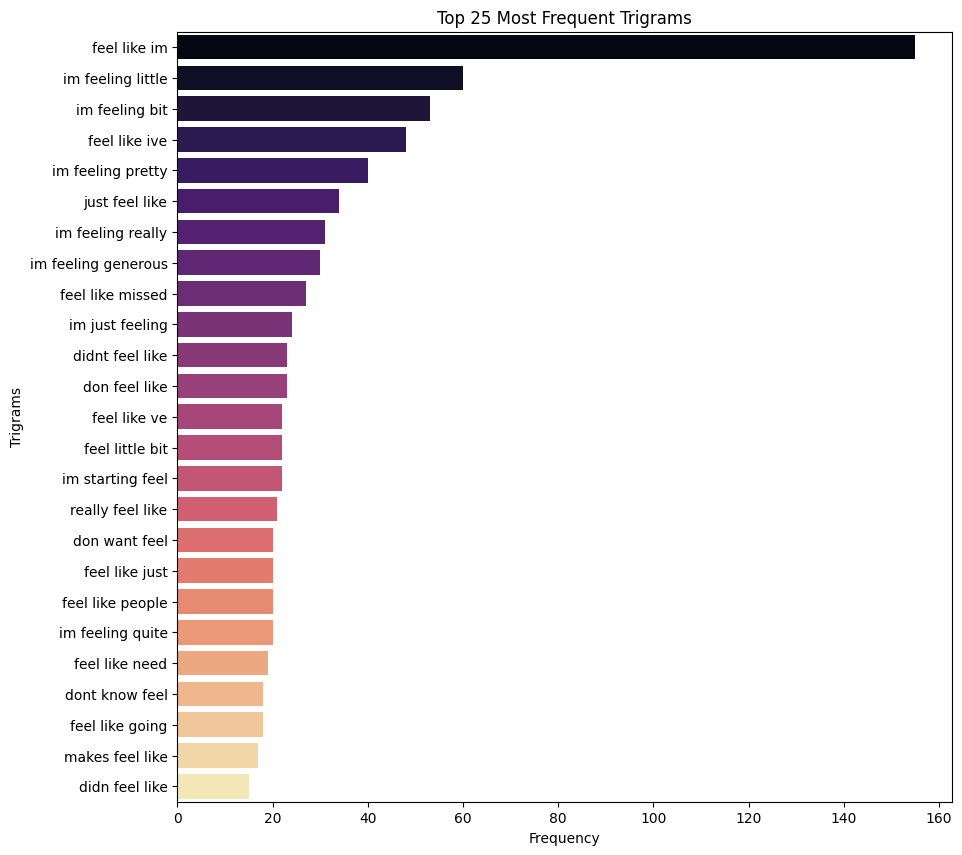

In [49]:
plot_top_ngrams(corpus, ngram_range=(3, 3), name="Trigrams", palette="magma")

### **Observation (Tri-grams)**
1. `feel like im` and `im feeling little` are the most frequent triples.
2. Most frequent triples are templates around "feel", so the discriminating information sits in the word that follows them. This is why we keep stop-words and word order for the LSTM.

# **Data Pre-Processing (for the LSTM)**

## **1. Train / Validation / Test Split**
Stratified 80 / 10 / 10 split so every emotion keeps the same proportion in each part. Validation is used during training (early stopping), and test is used only once at the end.

In [50]:
from sklearn.model_selection import train_test_split

SEED = 42  # Define SEED for reproducibility
np.random.seed(SEED)

# Create a reverse mapping from emotion names to integer IDs
emotion_to_id = {emotion: i for i, emotion in enumerate(LABEL_NAMES)}
y = df["emotion"].map(emotion_to_id).values  # Map string emotions back to integers

X_train_txt, X_temp_txt, y_train, y_temp = train_test_split(
    df["cleaned_text"], y, test_size=0.2, stratify=y, random_state=SEED)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(
    X_temp_txt, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print(f"Train {len(X_train_txt)} | Val {len(X_val_txt)} | Test {len(X_test_txt)}")

Train 12775 | Val 1597 | Test 1597


## **2. Tokenizer and Padding**
Convert words to integers and pad every text to the same length. The tokenizer is fit on the **training set only**, to avoid data leakage.

In [51]:
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

# Define MAX_VOCAB and MAX_LEN
MAX_VOCAB = 10000 # Example: Keep top 10,000 words
MAX_LEN = 50    # Example: Pad sequences to a maximum length of 50 words

tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_txt)
word_index = tokenizer.word_index
VOCAB_SIZE = min(MAX_VOCAB, len(word_index) + 1)

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train, X_val, X_test = map(to_padded, (X_train_txt, X_val_txt, X_test_txt))
print("Padded shape:", X_train.shape, "| Vocab size:", VOCAB_SIZE)

TensorFlow 2.21.0
Padded shape: (12775, 50) | Vocab size: 10000


In [52]:
# Save the tokenizer (needed later to predict on new text)
with open("tokenizer.pkl", "wb") as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [53]:
# One example: text -> integers
print(X_train_txt.iloc[0])
print(X_train[0])

i feel scared when my father suddenly opens a door
[   2    3  356   34   11  828  728 4563    7 1065    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


## **3. Class Weights**
`surprise` has far fewer samples than `joy`, so rare classes get a larger weight. A mistake on a rare class then costs more during training.

In [54]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights))
{LABEL_NAMES[k]: round(v, 2) for k, v in class_weight.items()}

{'sadness': np.float64(0.57),
 'joy': np.float64(0.5),
 'love': np.float64(2.05),
 'anger': np.float64(1.24),
 'fear': np.float64(1.38),
 'surprise': np.float64(4.68)}

### **1. TF-IDF (Term Frequency-Inverse Document Frequency)**
TF-IDF scores help identify the importance of words in the dataset

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(df['cleaned_text'])

tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out())

tfidf_df.head()

,aa,aaaaaaand,aaaaand,aaaand,aac,aahhh,aaron,ab,abandon,abandoned,...,zonisamide,zoo,zoom,zooming,zooms,zq,zucchini,zum,zumba,zz
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### **2. Bag of Words**
Bag of Words converts text into a matrix of token counts.

In [56]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

bow_matrix = vectorizer.fit_transform(df['cleaned_text'])

bow_df = pd.DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())

bow_df.head()

,aa,aaaaaaand,aaaaand,aaaand,aac,aahhh,aaron,ab,abandon,abandoned,...,zonisamide,zoo,zoom,zooming,zooms,zq,zucchini,zum,zumba,zz
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### **3. Word2Vec**
Word2Vec represents each word as a vector. You'll need the gensim library for this.

In [57]:
import numpy as np
from gensim.models import Word2Vec
import pandas as pd # Ensure pandas is imported if not already

# Step 1: Create Word2Vec model
word2vec_model = Word2Vec(sentences=df['tokens'], vector_size=100, window=5, min_count=1, workers=4)

# Step 2: Define function to get Word2Vec vectors
def get_word2vec_vector(text):
    # Re-tokenize text for consistency if `cleaned_text` is a string and `tokens` is a list of lists
    words = text.split() if isinstance(text, str) else text # Handle cases where 'text' might already be a list of tokens
    word_vectors = [word2vec_model.wv[word] for word in words if word in word2vec_model.wv]

    if len(word_vectors) == 0:
        # Return a zero vector of the correct size if no words are found in the model
        return np.zeros(word2vec_model.vector_size)

    return np.mean(word_vectors, axis=0)

# Step 3: Apply the function to each text entry in the DataFrame
# Using `df['cleaned_text']` assuming it's a string that needs splitting into words
word2vec_matrix = np.array([get_word2vec_vector(text) for text in df['cleaned_text']])

print(word2vec_matrix.shape)


(15969, 100)


This `word2vec_matrix` now contains the Word2Vec embeddings for each document in your dataset. Each row in the matrix corresponds to a document, and each column represents a dimension in the word embedding space.

In [58]:
print(word2vec_matrix)

[[-0.21158831  0.63268495  0.21288151 ... -0.69298249  0.13376673
   0.21942337]
 [-0.1590597   0.40042448  0.13024361 ... -0.44301662  0.08035301
   0.13975726]
 [-0.20588863  0.52942514  0.16779497 ... -0.59203517  0.11002365
   0.1840826 ]
 ...
 [-0.19311079  0.57720274  0.18880056 ... -0.63663918  0.12587684
   0.20141819]
 [-0.23612241  0.60114217  0.18782337 ... -0.67590952  0.14296958
   0.20518364]
 [-0.17224722  0.49742964  0.1670609  ... -0.54896373  0.10658967
   0.17239594]]


### **4.doc2Vec**
Doc2Vec is an extension of Word2Vec that generates vector representations for entire documents or sentences, enabling document-level semantic analysis.

In [59]:
import numpy as np
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
import pandas as pd # Ensure pandas is imported if not already

# Step 1: Create TaggedDocuments from the 'tokens' column
tagged_data = [TaggedDocument(words=tokens, tags=[str(i)]) for i, tokens in enumerate(df['tokens'])]

# Step 2: Create Doc2Vec model
doc2vec_model = Doc2Vec(vector_size=100, window=5, min_count=1, workers=4, epochs=10)
doc2vec_model.build_vocab(tagged_data)
doc2vec_model.train(tagged_data, total_examples=doc2vec_model.corpus_count, epochs=doc2vec_model.epochs)

# Step 3: Define function to get Doc2Vec vectors
def get_doc2vec_vector(doc_id):
    # Retrieve the document vector by its tag (which is the document ID)
    return doc2vec_model.dv[str(doc_id)]

# Step 4: Apply the function to each document in the DataFrame
doc2vec_matrix = np.array([get_doc2vec_vector(i) for i in range(len(df['tokens']))])

print(doc2vec_matrix.shape)


(15969, 100)


This `doc2vec_matrix` contains the Doc2Vec embeddings for each document in your dataset. Each row in the matrix corresponds to a document, and each column represents a dimension in the document embedding space.

In [60]:
print(doc2vec_matrix)

[[-8.78246408e-03  6.76843396e-04 -7.60924909e-03 ... -1.13583086e-02
   1.30136842e-02 -4.67978243e-04]
 [-1.53673450e-02  1.58349201e-02  2.05687073e-04 ... -3.00643072e-02
   9.39422846e-03  5.71169704e-03]
 [-9.28026345e-03 -3.29598971e-03  1.20963147e-02 ... -8.92574713e-03
   9.74782836e-03 -6.07902743e-03]
 ...
 [ 7.37179304e-04  7.99586810e-03  1.51365600e-03 ... -1.78264230e-02
   1.26406271e-02  3.65002337e-03]
 [-7.91313685e-03  8.34292080e-03  8.45100917e-03 ... -1.42615112e-02
  -8.36292375e-03  6.74771238e-03]
 [ 2.32894439e-03 -4.29650070e-03  5.05946155e-05 ... -1.14962105e-02
   5.21583669e-03 -9.24554374e-03]]


### **5. GloVe (Global Vectors for Word Representation)**
For GloVe, you can either train your own model or use pre-trained vectors.

In [61]:
glove_file = '/content/glove.6B.100d.txt'
glove_dict = {}

# Download GloVe if not already present
import os
import urllib.request
import zipfile

if not os.path.exists(glove_file):
    print("Downloading GloVe embeddings...")
    glove_zip_path = '/content/glove.6B.zip'
    urllib.request.urlretrieve('http://nlp.stanford.edu/data/glove.6B.zip', glove_zip_path)

    print("Extracting GloVe embeddings...")
    with zipfile.ZipFile(glove_zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')
    os.remove(glove_zip_path)
    print("GloVe embeddings downloaded and extracted.")
else:
    print("GloVe embeddings already present.")

Extracting GloVe embeddings...
GloVe embeddings downloaded and extracted.


In [62]:
# Load GloVe vectors
with open(glove_file, 'r', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        vector = np.asarray(values[1:], dtype='float32')
        glove_dict[word] = vector

# Create GloVe matrix
def get_glove_vector(text):
    words = text.split()
    word_vectors = [glove_dict[word] for word in words if word in glove_dict]
    return np.mean(word_vectors, axis=0) if word_vectors else np.zeros(100)

glove_matrix = np.array([get_glove_vector(text) for text in df['cleaned_text']])

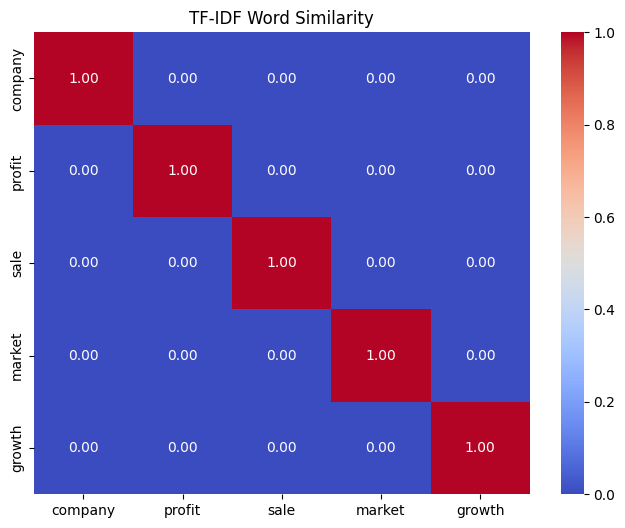

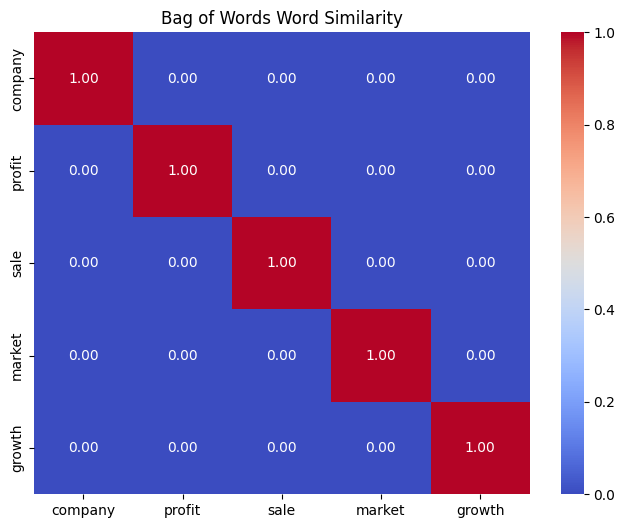

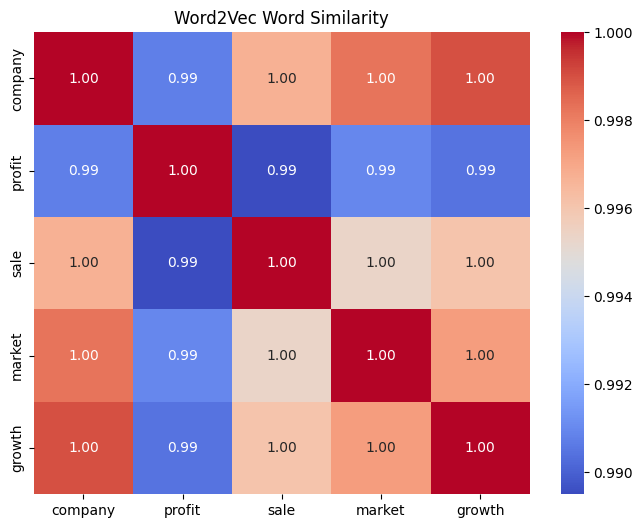

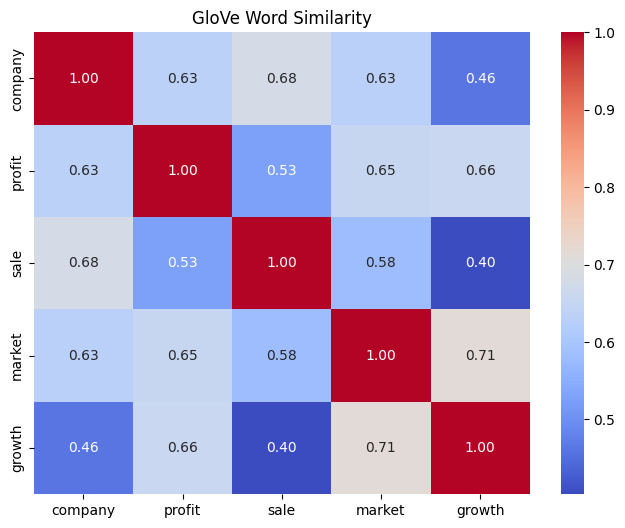

In [63]:
from sklearn.metrics.pairwise import cosine_similarity

# Defining a function to compute and plot a heatmap for a given matrix and title
def plot_similarity_heatmap(matrix, title, words):
    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix, cmap='coolwarm', annot=True, fmt=".2f", xticklabels=words, yticklabels=words)
    plt.title(title)
    plt.show()

# Example set of words for comparison
words = ['company', 'profit', 'sale', 'market', 'growth']

# Function to get vectors or fallback to a zero vector if the word is not found
def get_vector(model, word, fallback_dim=100):
    try:
        return model[word]
    except KeyError:
        # Return a zero vector if the word is not found
        print(f"Word '{word}' not found in vocabulary.")
        return np.zeros(fallback_dim)

### 1. TF-IDF Similarity Matrix
# Check if the words exist in the TF-IDF vocabulary
tfidf_vectors = [tfidf_df[word].values if word in tfidf_df.columns else np.zeros(tfidf_df.shape[1]) for word in words]

# Compute cosine similarity matrix
tfidf_similarity = cosine_similarity(tfidf_vectors)

# Plot heatmap for TF-IDF
plot_similarity_heatmap(tfidf_similarity, 'TF-IDF Word Similarity', words)

### 2. Bag of Words (BoW) Similarity Matrix
# Check if the words exist in the BoW vocabulary
bow_vectors = [bow_df[word].values if word in bow_df.columns else np.zeros(bow_df.shape[1]) for word in words]

# Compute cosine similarity matrix
bow_similarity = cosine_similarity(bow_vectors)

# Plot heatmap for Bag of Words
plot_similarity_heatmap(bow_similarity, 'Bag of Words Word Similarity', words)

### 3. Word2Vec Similarity Matrix
# Get Word2Vec vectors or fallback to zero vector for missing words
word2vec_vectors = [get_vector(word2vec_model.wv, word) for word in words]

# Compute cosine similarity matrix
word2vec_similarity = cosine_similarity(word2vec_vectors)

# Plot heatmap for Word2Vec
plot_similarity_heatmap(word2vec_similarity, 'Word2Vec Word Similarity', words)

### 4. GloVe Similarity Matrix
# Get GloVe vectors or fallback to zero vector for missing words
glove_vectors = [get_vector(glove_dict, word) for word in words]

# Compute cosine similarity matrix
glove_similarity = cosine_similarity(glove_vectors)

# Plot heatmap for GloVe
plot_similarity_heatmap(glove_similarity, 'GloVe Word Similarity', words)


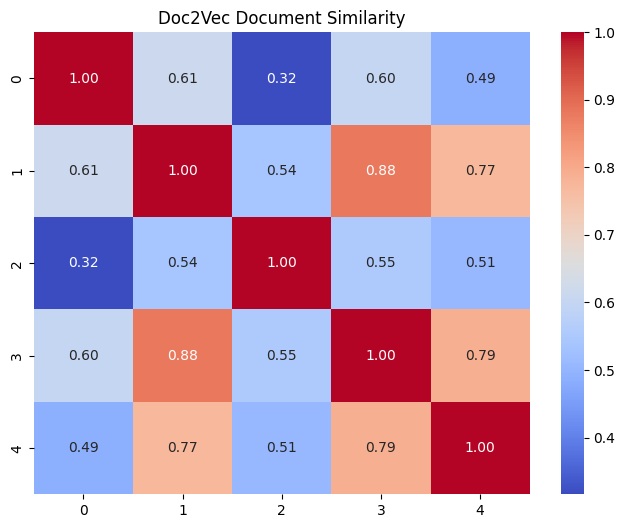

In [64]:
# Example set of document indices for comparison (you should use document indices, not words)
doc_ids = [0, 1, 2, 3, 4]  # Replace with valid document indices in your data

# Get Doc2Vec vectors for the given document IDs
doc2vec_vectors = [doc2vec_model.dv[i] for i in doc_ids]  # Retrieve document vectors by their ID

# Compute cosine similarity matrix for documents
doc2vec_similarity = cosine_similarity(doc2vec_vectors)

# Plot heatmap for Doc2Vec document similarity
plot_similarity_heatmap(doc2vec_similarity, 'Doc2Vec Document Similarity', doc_ids)


Word2Vec Similarity has the highest overall cosine similarity scores, indicating strong semantic relationships between the chosen words (company, profit, sale, market, growth).

Doc2Vec Similarity also shows good similarity between the selected documents.

GloVe Similarity exhibits moderate to high cosine similarity, capturing global co-occurrence patterns effectively.

In contrast, TF-IDF Word Similarity and Bag of Words Word Similarity graphs typically show very low or zero similarity between different words, as these methods do not inherently capture semantic relationships between words; they focus more on individual word importance or frequency within a document.

# **Applying the LSTM Model**

The five steps: **1. Create** the model, **2. Define** the architecture, **3. Compile**, **4. Fit**, **5. Evaluate**.

### **1. Creating a model**

In [65]:
from tensorflow.keras.models import Sequential

model = Sequential(name="glove_lstm_emotion")

### **2. Defining the architecture**
Input (70 integers) → frozen GloVe `Embedding` → `LSTM(128)` → `LSTM(64)` → `Dense(64)` → `Dense(6, softmax)`, with dropout in between to reduce overfitting.

In [66]:
from tensorflow.keras.layers import LSTM, Dense, Dropout, Embedding, Input
from tensorflow.keras.models import Sequential # Ensure Sequential is imported here
import numpy as np # Needed for np.zeros and np.array

# Re-initialize the model to clear previous configuration
model = Sequential(name="glove_lstm_emotion")

# Define missing variables:
# EMBEDDING_DIM is 100 for glove.6B.100d.txt
EMBEDDING_DIM = 100

# NUM_CLASSES is the number of unique emotions in LABEL_NAMES
# LABEL_NAMES is available in the kernel state, containing 6 emotions
NUM_CLASSES = len(LABEL_NAMES)

# Create embedding_matrix using word_index from tokenizer and glove_dict
embedding_matrix = np.zeros((VOCAB_SIZE, EMBEDDING_DIM))
for word, i in word_index.items():
    if i < VOCAB_SIZE: # Ensure index is within the vocabulary size
        embedding_vector = glove_dict.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

model.add(Input(shape=(MAX_LEN,)))
model.add(Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    weights=[embedding_matrix],   # pre-trained GloVe vectors
    trainable=False,              # frozen; set True to fine-tune
    mask_zero=True,               # LSTM ignores padding tokens
    name="glove_embedding",
))
model.add(LSTM(128, return_sequences=True, name="lstm_1"))
model.add(Dropout(0.4))
model.add(LSTM(64, name="lstm_2"))
model.add(Dropout(0.4))
model.add(Dense(64, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(NUM_CLASSES, activation="softmax", name="output"))

model.summary()

Model: "glove_lstm_emotion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ glove_embedding (Embedding)     │ (None, 50, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50, 128)        │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,171,206 (4.47 MB)

 Trainable params: 171,206 (668.77 KB)

 Non-trainable params: 1,000,000 (3.81 MB)

### **3. Compile the model**

In [67]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",   # integer labels, multi-class
    metrics=["accuracy"],
)

### **4. Fit the model**
Early stopping stops training when validation loss stops improving and restores the best weights. `ReduceLROnPlateau` halves the learning rate when it stalls.

In [85]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Define EPOCHS and BATCH_SIZE
EPOCHS = 20
BATCH_SIZE = 32

callbacks = [
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/20
400/400 - 10s - 24ms/step - accuracy: 0.9332 - loss: 0.1493 - val_accuracy: 0.9242 - val_loss: 0.2268 - learning_rate: 1.2500e-04
Epoch 2/20
400/400 - 5s - 13ms/step - accuracy: 0.9340 - loss: 0.1406 - val_accuracy: 0.9242 - val_loss: 0.2242 - learning_rate: 1.2500e-04
Epoch 3/20
400/400 - 4s - 11ms/step - accuracy: 0.9371 - loss: 0.1378 - val_accuracy: 0.9230 - val_loss: 0.2460 - learning_rate: 1.2500e-04
Epoch 4/20

Epoch 4: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
400/400 - 6s - 16ms/step - accuracy: 0.9373 - loss: 0.1339 - val_accuracy: 0.9261 - val_loss: 0.2242 - learning_rate: 1.2500e-04
Epoch 5/20
400/400 - 5s - 13ms/step - accuracy: 0.9421 - loss: 0.1246 - val_accuracy: 0.9280 - val_loss: 0.2240 - learning_rate: 6.2500e-05
Epoch 6/20
400/400 - 4s - 11ms/step - accuracy: 0.9411 - loss: 0.1258 - val_accuracy: 0.9280 - val_loss: 0.2220 - learning_rate: 6.2500e-05
Epoch 7/20
400/400 - 5s - 13ms/step - accuracy: 0.9440 - loss: 0.1197 - val_accurac

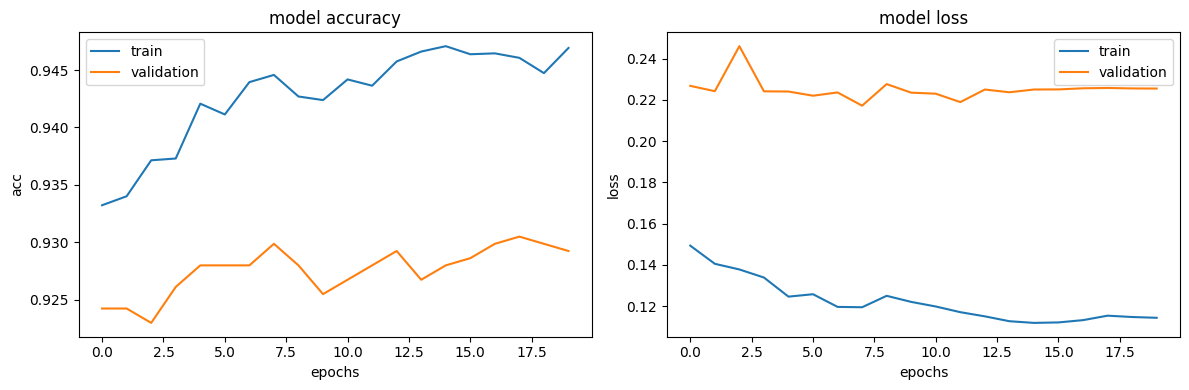

In [86]:
# Plot the results (accuracy and loss)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("model accuracy"); ax[0].set_xlabel("epochs"); ax[0].set_ylabel("acc"); ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("model loss"); ax[1].set_xlabel("epochs"); ax[1].set_ylabel("loss"); ax[1].legend()

plt.tight_layout()
plt.savefig("model_curves.png", dpi=120)
plt.show()

### **5. Evaluate the model**

In [87]:
# Evaluate the model on test data

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.2386
Test Accuracy: 0.9048


In [88]:
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 90.48%


In [89]:
# Best training accuracy
train_accuracy = max(history.history["accuracy"])

# Best validation accuracy
val_accuracy = max(history.history["val_accuracy"])

print(f"Best Training Accuracy   : {train_accuracy * 100:.2f}%")
print(f"Best Validation Accuracy : {val_accuracy * 100:.2f}%")
print(f"Test Accuracy            : {test_accuracy * 100:.2f}%")

Best Training Accuracy   : 94.71%
Best Validation Accuracy : 93.05%
Test Accuracy            : 90.48%


In [90]:
_, train_acc = model.evaluate(X_train, y_train, verbose=0)
_, val_acc = model.evaluate(X_val, y_val, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Train: %.3f | Validation: %.3f | Test: %.3f" % (train_acc, val_acc, test_acc))

Train: 0.952 | Validation: 0.929 | Test: 0.905


In [91]:
# Predict probabilities for the test set, then take the class with the highest probability
yhat_probs = model.predict(X_test, verbose=0)
yhat_classes = np.argmax(yhat_probs, axis=1)
yhat_classes[:20]

array([0, 4, 3, 1, 1, 3, 2, 1, 0, 1, 3, 3, 3, 0, 1, 1, 4, 1, 4, 3])

In [92]:
from sklearn.metrics import classification_report

print(classification_report(y_test, yhat_classes, target_names=LABEL_NAMES, zero_division=0))

              precision    recall  f1-score   support

     Sadness       0.96      0.92      0.94       467
         Joy       0.96      0.89      0.92       535
        Love       0.73      0.94      0.82       130
       Anger       0.88      0.93      0.91       215
        Fear       0.90      0.84      0.87       193
    Surprise       0.71      0.96      0.81        57

    accuracy                           0.90      1597
   macro avg       0.86      0.91      0.88      1597
weighted avg       0.91      0.90      0.91      1597



# **Validation on New Sentences**
The same cleaning steps are applied to a new sentence, then it is converted to a padded sequence and passed to the model.

In [93]:
def predict_emotion(text, show_probs=False):
    cleaned = remove_unnecessary_characters(text).lower()
    padded = to_padded([cleaned])
    probs = model.predict(padded, verbose=0)[0]
    label = LABEL_NAMES[int(np.argmax(probs))]
    if show_probs:
        print({n: round(float(p), 3) for n, p in zip(LABEL_NAMES, probs)})
    return label

test_sentences = [
    "i feel so alone and hopeless today",
    "i am so happy and grateful for everything",
    "i feel a deep love for my family",
    "i am furious about how i was treated",
    "i am terrified of what might happen tomorrow",
    "i was amazed by how beautiful the view was",
    "i did not feel happy at all",
    "i feel so nervous before the exam",
]

for s in test_sentences:
    print(f"{predict_emotion(s):<9} <-  {s}")

Sadness   <-  i feel so alone and hopeless today
Joy       <-  i am so happy and grateful for everything
Sadness   <-  i feel a deep love for my family
Anger     <-  i am furious about how i was treated
Fear      <-  i am terrified of what might happen tomorrow
Surprise  <-  i was amazed by how beautiful the view was
Joy       <-  i did not feel happy at all
Fear      <-  i feel so nervous before the exam


In [94]:
# Look at the full probabilities for one sentence
predict_emotion("i was amazed by how beautiful the view was", show_probs=True)

{'Sadness': 0.0, 'Joy': 0.086, 'Love': 0.011, 'Anger': 0.0, 'Fear': 0.0, 'Surprise': 0.903}


'Surprise'

###Cross Validation

In [95]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def create_lstm_model():

    cv_model = Sequential([
        Embedding(
            input_dim=MAX_VOCAB_SIZE,
            output_dim=128
        ),

        LSTM(128),

        Dropout(0.5),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(NUM_CLASSES, activation="softmax")
    ])

    cv_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return cv_model

In [96]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

# Map MAX_VOCAB to MAX_VOCAB_SIZE used inside create_lstm_model
MAX_VOCAB_SIZE = MAX_VOCAB

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train), 1
):

    print(f"\n========== Fold {fold} ==========")

    # Create a fresh model
    cv_model = create_lstm_model()

    # Train
    cv_model.fit(
        X_train[train_idx],
        y_train[train_idx],
        epochs=10,
        batch_size=32,
        verbose=0
    )

    # Evaluate on validation fold
    fold_loss, fold_accuracy = cv_model.evaluate(
        X_train[val_idx],
        y_train[val_idx],
        verbose=0
    )

    cv_scores.append(fold_accuracy)

    print(f"Fold {fold} Accuracy: {fold_accuracy * 100:.2f}%")


========== Fold 1 ==========
Fold 1 Accuracy: 48.38%

========== Fold 2 ==========
Fold 2 Accuracy: 45.24%

========== Fold 3 ==========
Fold 3 Accuracy: 59.49%

========== Fold 4 ==========
Fold 4 Accuracy: 33.50%

========== Fold 5 ==========
Fold 5 Accuracy: 45.83%


###Display Accuracy for All 5 Folds

In [97]:
print("\nCross-Validation Results")
print("-" * 35)

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i} Accuracy: {score * 100:.2f}%")


Cross-Validation Results
-----------------------------------
Fold 1 Accuracy: 48.38%
Fold 2 Accuracy: 45.24%
Fold 3 Accuracy: 59.49%
Fold 4 Accuracy: 33.50%
Fold 5 Accuracy: 45.83%


###Standard Deviation

In [98]:
std_cv_accuracy = np.std(cv_scores)

print(
    f"Standard Deviation: "
    f"{std_cv_accuracy * 100:.2f}%"
)

Standard Deviation: 8.29%


In [99]:
print("========== 5-Fold Cross Validation ==========")

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("---------------------------------------------")
print(f"Mean Accuracy: {np.mean(cv_scores) * 100:.2f}%")
print(f"Std Deviation: {np.std(cv_scores) * 100:.2f}%")

========== 5-Fold Cross Validation ==========
Fold 1: 48.38%
Fold 2: 45.24%
Fold 3: 59.49%
Fold 4: 33.50%
Fold 5: 45.83%
---------------------------------------------
Mean Accuracy: 46.49%
Std Deviation: 8.29%


###Fine-Tuned LSTM Architecture

In [100]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout
)

fine_tuned_model = Sequential([

    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=128
    ),

    LSTM(
        128,
        return_sequences=True,
        dropout=0.2
    ),

    LSTM(
        64,
        dropout=0.2
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.4),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

fine_tuned_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 50, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,465,542 (5.59 MB)

 Trainable params: 1,465,542 (5.59 MB)

 Non-trainable params: 0 (0.00 B)

In [101]:
fine_tuned_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 50, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,465,542 (5.59 MB)

 Trainable params: 1,465,542 (5.59 MB)

 Non-trainable params: 0 (0.00 B)

###Fine-Tune the Learning Rate

Compile the model:

In [102]:
fine_tuned_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

A smaller learning rate allows the model to make smaller and more controlled updates during training.

ReduceLROnPlateau

In [103]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

###Fine-Tuned Model Training

In [104]:
EPOCHS = 20

BATCH_SIZE = 32

fine_history = fine_tuned_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[
        reduce_lr
    ],
    verbose=2
)

Epoch 1/20
400/400 - 7s - 17ms/step - accuracy: 0.1494 - loss: 1.7935 - val_accuracy: 0.0808 - val_loss: 1.7983 - learning_rate: 5.0000e-04
Epoch 2/20
400/400 - 5s - 12ms/step - accuracy: 0.1395 - loss: 1.7928 - val_accuracy: 0.0814 - val_loss: 1.7975 - learning_rate: 5.0000e-04
Epoch 3/20
400/400 - 6s - 14ms/step - accuracy: 0.1412 - loss: 1.7927 - val_accuracy: 0.0802 - val_loss: 1.7970 - learning_rate: 5.0000e-04
Epoch 4/20
400/400 - 4s - 11ms/step - accuracy: 0.1750 - loss: 1.7925 - val_accuracy: 0.0814 - val_loss: 1.8034 - learning_rate: 5.0000e-04
Epoch 5/20
400/400 - 5s - 12ms/step - accuracy: 0.1726 - loss: 1.7898 - val_accuracy: 0.3112 - val_loss: 1.7914 - learning_rate: 5.0000e-04
Epoch 6/20
400/400 - 6s - 14ms/step - accuracy: 0.2619 - loss: 1.6252 - val_accuracy: 0.2091 - val_loss: 1.4283 - learning_rate: 5.0000e-04
Epoch 7/20
400/400 - 4s - 10ms/step - accuracy: 0.4130 - loss: 1.2923 - val_accuracy: 0.5441 - val_loss: 1.1940 - learning_rate: 5.0000e-04
Epoch 8/20
400/400 -

In [105]:
# Save the fine-tuned LSTM model
fine_tuned_model.save('fine_tuned_lstm_emotion.keras')
print("Fine-tuned LSTM model saved successfully!")

Fine-tuned LSTM model saved successfully!


###Compare Original vs Fine-Tuned Model

In [106]:
original_loss, original_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

fine_loss, fine_accuracy = fine_tuned_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Original LSTM Test Accuracy    : {original_accuracy * 100:.2f}%")
print(f"Fine-Tuned LSTM Test Accuracy  : {fine_accuracy * 100:.2f}%")

Original LSTM Test Accuracy    : 90.48%
Fine-Tuned LSTM Test Accuracy  : 88.79%


###Applying the GRU Model

###1. Create and Define the GRU Architecture

In [107]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

gru_model = Sequential([

    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=128
    ),

    GRU(
        128,
        dropout=0.2
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.4),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

gru_model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,387,718 (5.29 MB)

 Trainable params: 1,387,718 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

###2. Compile the GRU Model

In [108]:
gru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

###3. Fit the GRU Model

In [109]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

EPOCHS = 20
BATCH_SIZE = 32

gru_callbacks = [
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=gru_callbacks,
    verbose=2
)

Epoch 1/20
400/400 - 6s - 14ms/step - accuracy: 0.1809 - loss: 1.7944 - val_accuracy: 0.0827 - val_loss: 1.7901 - learning_rate: 0.0010
Epoch 2/20
400/400 - 3s - 8ms/step - accuracy: 0.1415 - loss: 1.7926 - val_accuracy: 0.0820 - val_loss: 1.7971 - learning_rate: 0.0010
Epoch 3/20

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
400/400 - 3s - 8ms/step - accuracy: 0.1451 - loss: 1.7913 - val_accuracy: 0.0833 - val_loss: 1.7975 - learning_rate: 0.0010
Epoch 4/20
400/400 - 5s - 12ms/step - accuracy: 0.1339 - loss: 1.7844 - val_accuracy: 0.1334 - val_loss: 1.7971 - learning_rate: 5.0000e-04
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
400/400 - 3s - 8ms/step - accuracy: 0.1299 - loss: 1.7727 - val_accuracy: 0.1209 - val_loss: 1.7963 - learning_rate: 5.0000e-04
Epoch 6/20
400/400 - 3s - 8ms/step - accuracy: 0.1642 - loss: 1.7606 - val_accuracy: 0.0958 - val_loss: 1.8274 - learning_rate: 2.5000e-04
Epoch 7/20

Epoch 7: R

### Evaluate the GRU Model

training, validation, and test accuracy:

In [110]:
train_accuracy = max(gru_history.history["accuracy"])
val_accuracy = max(gru_history.history["val_accuracy"])

_, test_accuracy = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Training Accuracy   : {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")
print(f"Test Accuracy       : {test_accuracy * 100:.2f}%")

Training Accuracy   : 21.49%
Validation Accuracy : 18.91%
Test Accuracy       : 18.53%


###5. Cross Validation — 5 Folds

In [111]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

def create_gru_model():

    cv_model = Sequential([

        Input(shape=(MAX_SEQUENCE_LENGTH,)),

        Embedding(
            input_dim=MAX_VOCAB_SIZE,
            output_dim=128
        ),

        GRU(128, dropout=0.2),

        Dense(64, activation="relu"),

        Dropout(0.4),

        Dense(NUM_CLASSES, activation="softmax")
    ])

    cv_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return cv_model

In [112]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

gru_cv_scores = []

# Map MAX_LEN to MAX_SEQUENCE_LENGTH for compatibility if needed, or override inside the loop
MAX_SEQUENCE_LENGTH = MAX_LEN

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train), 1
):

    print(f"\n========== Fold {fold} ==========")

    cv_model = create_gru_model()

    cv_model.fit(
        X_train[train_idx],
        y_train[train_idx],
        epochs=10,
        batch_size=32,
        verbose=0
    )

    _, fold_accuracy = cv_model.evaluate(
        X_train[val_idx],
        y_train[val_idx],
        verbose=0
    )

    gru_cv_scores.append(fold_accuracy)

    print(
        f"Fold {fold} Accuracy: "
        f"{fold_accuracy * 100:.2f}%"
    )


========== Fold 1 ==========
Fold 1 Accuracy: 91.43%

========== Fold 2 ==========
Fold 2 Accuracy: 91.39%

========== Fold 3 ==========
Fold 3 Accuracy: 91.70%

========== Fold 4 ==========
Fold 4 Accuracy: 91.35%

========== Fold 5 ==========
Fold 5 Accuracy: 92.68%


In [113]:
print("\n========== GRU Cross Validation ==========")

for i, score in enumerate(gru_cv_scores, 1):
    print(f"Fold {i}: {score * 100:.2f}%")

print(
    f"\nMean CV Accuracy: "
    f"{np.mean(gru_cv_scores) * 100:.2f}%"
)

print(
    f"CV Standard Deviation: "
    f"{np.std(gru_cv_scores) * 100:.2f}%"
)


========== GRU Cross Validation ==========
Fold 1: 91.43%
Fold 2: 91.39%
Fold 3: 91.70%
Fold 4: 91.35%
Fold 5: 92.68%

Mean CV Accuracy: 91.71%
CV Standard Deviation: 0.50%


###6. Fine-Tuning the GRU Model

In [114]:
fine_tuned_gru = Sequential([

    Input(shape=(MAX_SEQUENCE_LENGTH,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=128
    ),

    GRU(
        128,
        return_sequences=True,
        dropout=0.2
    ),

    GRU(
        64,
        dropout=0.2
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.4),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

fine_tuned_gru.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_14 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_6 (GRU)                     │ (None, 50, 128)        │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_7 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,420,870 (5.42 MB)

 Trainable params: 1,420,870 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

###Compile the Fine-Tuned GRU

In [115]:
fine_tuned_gru.compile(
    optimizer=Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

###Train the Fine-Tuned GRU

In [116]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

gru_fine_callbacks = [

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

gru_fine_history = fine_tuned_gru.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=gru_fine_callbacks,
    verbose=2
)

Epoch 1/20
400/400 - 8s - 21ms/step - accuracy: 0.1684 - loss: 1.7934 - val_accuracy: 0.0827 - val_loss: 1.8005 - learning_rate: 5.0000e-04
Epoch 2/20
400/400 - 8s - 20ms/step - accuracy: 0.1902 - loss: 1.7929 - val_accuracy: 0.0833 - val_loss: 1.7985 - learning_rate: 5.0000e-04
Epoch 3/20
400/400 - 5s - 13ms/step - accuracy: 0.1523 - loss: 1.7925 - val_accuracy: 0.1215 - val_loss: 1.8077 - learning_rate: 5.0000e-04
Epoch 4/20
400/400 - 9s - 23ms/step - accuracy: 0.1378 - loss: 1.7924 - val_accuracy: 0.3275 - val_loss: 1.7943 - learning_rate: 5.0000e-04
Epoch 5/20
400/400 - 5s - 13ms/step - accuracy: 0.1690 - loss: 1.7919 - val_accuracy: 0.0845 - val_loss: 1.7966 - learning_rate: 5.0000e-04
Epoch 6/20
400/400 - 5s - 13ms/step - accuracy: 0.1555 - loss: 1.7895 - val_accuracy: 0.3075 - val_loss: 1.7924 - learning_rate: 5.0000e-04
Epoch 7/20
400/400 - 4s - 10ms/step - accuracy: 0.1335 - loss: 1.7799 - val_accuracy: 0.0858 - val_loss: 1.8187 - learning_rate: 5.0000e-04
Epoch 8/20

Epoch 8:

In [117]:
# Save the fine-tuned GRU model
fine_tuned_gru.save('fine_tuned_gru_emotion.keras')
print("Fine-tuned GRU model saved successfully!")

Fine-tuned GRU model saved successfully!


###Final Evaluation

In [118]:
import numpy as np

y_pred_prob = fine_tuned_gru.predict(
    X_test,
    verbose=0
)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

In [119]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

Accuracy : 40.33%
Precision: 43.04%
Recall   : 40.33%
F1 Score : 39.09%


###Classification Report

In [120]:
from sklearn.metrics import classification_report

LABEL_NAMES = [
    "sadness",
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=LABEL_NAMES,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     sadness       0.44      0.53      0.48       467
         joy       0.52      0.22      0.31       535
        love       0.38      0.61      0.47       130
       anger       0.42      0.58      0.49       215
        fear       0.26      0.26      0.26       193
    surprise       0.22      0.42      0.29        57

    accuracy                           0.40      1597
   macro avg       0.37      0.44      0.38      1597
weighted avg       0.43      0.40      0.39      1597



###Confusion Matrix

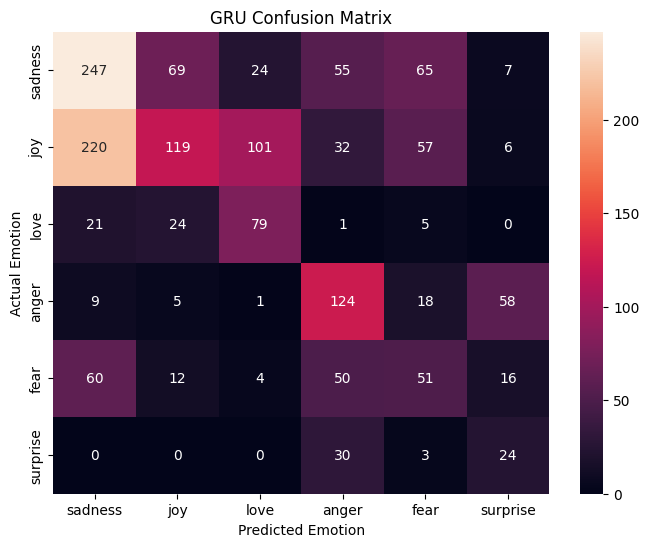

In [121]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("GRU Confusion Matrix")

plt.show()

###Applying the Bidirectional LSTM Model

Create and Define the BiLSTM Architecture

In [122]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Dropout,
    Bidirectional
)
from tensorflow.keras.optimizers import Adam

bilstm_model = Sequential([

    Input(shape=(MAX_SEQUENCE_LENGTH,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=128
    ),

    Bidirectional(
        LSTM(
            128,
            dropout=0.2
        )
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.4),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

bilstm_model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_15 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,560,006 (5.95 MB)

 Trainable params: 1,560,006 (5.95 MB)

 Non-trainable params: 0 (0.00 B)

###Compile the BiLSTM Model

In [123]:
bilstm_model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

###Fit the BiLSTM Model

In [124]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

EPOCHS = 20
BATCH_SIZE = 32

bilstm_callbacks = [

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

bilstm_history = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=bilstm_callbacks,
    verbose=2
)

Epoch 1/20
400/400 - 7s - 18ms/step - accuracy: 0.3478 - loss: 1.5191 - val_accuracy: 0.7226 - val_loss: 0.7997 - learning_rate: 0.0010
Epoch 2/20
400/400 - 6s - 14ms/step - accuracy: 0.8223 - loss: 0.5290 - val_accuracy: 0.8729 - val_loss: 0.3546 - learning_rate: 0.0010
Epoch 3/20
400/400 - 4s - 11ms/step - accuracy: 0.9137 - loss: 0.2817 - val_accuracy: 0.8973 - val_loss: 0.3093 - learning_rate: 0.0010
Epoch 4/20
400/400 - 10s - 25ms/step - accuracy: 0.9449 - loss: 0.1683 - val_accuracy: 0.8710 - val_loss: 0.4129 - learning_rate: 0.0010
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
400/400 - 4s - 11ms/step - accuracy: 0.9577 - loss: 0.1348 - val_accuracy: 0.9017 - val_loss: 0.3502 - learning_rate: 0.0010
Epoch 6/20
400/400 - 4s - 11ms/step - accuracy: 0.9754 - loss: 0.0783 - val_accuracy: 0.9048 - val_loss: 0.3676 - learning_rate: 5.0000e-04
Epoch 7/20

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
400/400 - 5s -

###Evaluate the BiLSTM Model
Only Test **Accuracy**

In [125]:
_, bilstm_test_accuracy = bilstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"BiLSTM Test Accuracy: "
    f"{bilstm_test_accuracy * 100:.2f}%"
)

BiLSTM Test Accuracy: 89.79%


Training, Validation and Test Accuracy

In [126]:
train_accuracy = max(
    bilstm_history.history["accuracy"]
)

val_accuracy = max(
    bilstm_history.history["val_accuracy"]
)

_, test_accuracy = bilstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"Training Accuracy   : "
    f"{train_accuracy * 100:.2f}%"
)

print(
    f"Validation Accuracy : "
    f"{val_accuracy * 100:.2f}%"
)

print(
    f"Test Accuracy       : "
    f"{test_accuracy * 100:.2f}%"
)

Training Accuracy   : 99.48%
Validation Accuracy : 91.11%
Test Accuracy       : 89.79%


###Cross Validation — 5 Folds

In [127]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

def create_bilstm_model():

    cv_model = Sequential([

        Input(shape=(MAX_SEQUENCE_LENGTH,)),

        Embedding(
            input_dim=MAX_VOCAB_SIZE,
            output_dim=128
        ),

        Bidirectional(
            LSTM(
                128,
                dropout=0.2
            )
        ),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.4),

        Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])

    cv_model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return cv_model

In [128]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

bilstm_cv_scores = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train), 1
):

    print(f"\n========== Fold {fold} ==========")

    cv_model = create_bilstm_model()

    cv_model.fit(
        X_train[train_idx],
        y_train[train_idx],
        epochs=10,
        batch_size=32,
        verbose=0
    )

    _, fold_accuracy = cv_model.evaluate(
        X_train[val_idx],
        y_train[val_idx],
        verbose=0
    )

    bilstm_cv_scores.append(
        fold_accuracy
    )

    print(
        f"Fold {fold} Accuracy: "
        f"{fold_accuracy * 100:.2f}%"
    )


========== Fold 1 ==========
Fold 1 Accuracy: 89.24%

========== Fold 2 ==========
Fold 2 Accuracy: 89.75%

========== Fold 3 ==========
Fold 3 Accuracy: 90.02%

========== Fold 4 ==========
Fold 4 Accuracy: 87.79%

========== Fold 5 ==========
Fold 5 Accuracy: 91.04%


In [129]:
print("\n========== BiLSTM Cross Validation ==========")

for i, score in enumerate(
    bilstm_cv_scores, 1
):
    print(
        f"Fold {i}: "
        f"{score * 100:.2f}%"
    )

print(
    f"\nMean CV Accuracy: "
    f"{np.mean(bilstm_cv_scores) * 100:.2f}%"
)

print(
    f"CV Standard Deviation: "
    f"{np.std(bilstm_cv_scores) * 100:.2f}%"
)


========== BiLSTM Cross Validation ==========
Fold 1: 89.24%
Fold 2: 89.75%
Fold 3: 90.02%
Fold 4: 87.79%
Fold 5: 91.04%

Mean CV Accuracy: 89.57%
CV Standard Deviation: 1.06%


###Fine-Tuning the BiLSTM

In [130]:
fine_tuned_bilstm = Sequential([

    Input(shape=(MAX_SEQUENCE_LENGTH,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=128
    ),

    Bidirectional(
        LSTM(
            128,
            return_sequences=True,
            dropout=0.2
        )
    ),

    Bidirectional(
        LSTM(
            64,
            dropout=0.2
        )
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.4),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

fine_tuned_bilstm.summary()

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_21 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 50, 256)        │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,716,166 (6.55 MB)

 Trainable params: 1,716,166 (6.55 MB)

 Non-trainable params: 0 (0.00 B)

###Compile the Fine-Tuned BiLSTM

In [131]:
fine_tuned_bilstm.compile(
    optimizer=Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

###Train the Fine-Tuned BiLSTM

In [132]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

bilstm_fine_callbacks = [

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

bilstm_fine_history = fine_tuned_bilstm.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=bilstm_fine_callbacks,
    verbose=2
)

Epoch 1/20
400/400 - 13s - 34ms/step - accuracy: 0.2252 - loss: 1.7162 - val_accuracy: 0.3732 - val_loss: 1.4298 - learning_rate: 5.0000e-04
Epoch 2/20
400/400 - 9s - 23ms/step - accuracy: 0.5581 - loss: 1.0519 - val_accuracy: 0.7451 - val_loss: 0.7412 - learning_rate: 5.0000e-04
Epoch 3/20
400/400 - 7s - 17ms/step - accuracy: 0.7611 - loss: 0.5287 - val_accuracy: 0.8190 - val_loss: 0.5813 - learning_rate: 5.0000e-04
Epoch 4/20
400/400 - 9s - 21ms/step - accuracy: 0.9061 - loss: 0.2851 - val_accuracy: 0.8936 - val_loss: 0.3322 - learning_rate: 5.0000e-04
Epoch 5/20
400/400 - 7s - 17ms/step - accuracy: 0.9460 - loss: 0.1841 - val_accuracy: 0.8910 - val_loss: 0.3658 - learning_rate: 5.0000e-04
Epoch 6/20

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
400/400 - 9s - 22ms/step - accuracy: 0.9516 - loss: 0.1519 - val_accuracy: 0.8986 - val_loss: 0.3693 - learning_rate: 5.0000e-04
Epoch 7/20
400/400 - 8s - 21ms/step - accuracy: 0.9714 - loss: 0.0913 - val_accura

In [133]:
# Save the fine-tuned BiLSTM model
fine_tuned_bilstm.save('fine_tuned_bilstm_emotion.keras')
print("Fine-tuned BiLSTM model saved successfully!")

Fine-tuned BiLSTM model saved successfully!


###Final Evaluation

In [134]:
import numpy as np

y_pred_prob = fine_tuned_bilstm.predict(
    X_test,
    verbose=0
)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

In [135]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

Accuracy : 90.92%
Precision: 91.22%
Recall   : 90.92%
F1 Score : 91.02%


###Classification Report

In [136]:
from sklearn.metrics import classification_report

LABEL_NAMES = [
    "sadness",
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=LABEL_NAMES,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     sadness       0.98      0.94      0.96       467
         joy       0.94      0.92      0.93       535
        love       0.74      0.81      0.77       130
       anger       0.87      0.93      0.90       215
        fear       0.87      0.88      0.87       193
    surprise       0.79      0.86      0.82        57

    accuracy                           0.91      1597
   macro avg       0.87      0.89      0.88      1597
weighted avg       0.91      0.91      0.91      1597



###Confusion Matrix

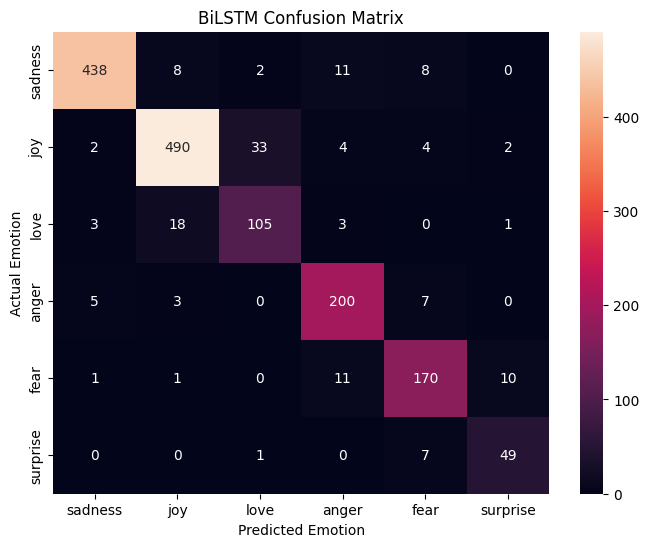

In [137]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("BiLSTM Confusion Matrix")

plt.show()

###LSTM vs GRU vs BiLSTM

In [138]:
_, lstm_test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

_, gru_test_accuracy = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

_, bilstm_test_accuracy = bilstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

_, fine_bilstm_test_accuracy = fine_tuned_bilstm.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"LSTM              : "
    f"{lstm_test_accuracy * 100:.2f}%"
)

print(
    f"GRU               : "
    f"{gru_test_accuracy * 100:.2f}%"
)

print(
    f"BiLSTM             : "
    f"{bilstm_test_accuracy * 100:.2f}%"
)

print(
    f"Fine-Tuned BiLSTM  : "
    f"{fine_bilstm_test_accuracy * 100:.2f}%"
)

LSTM              : 90.48%
GRU               : 18.53%
BiLSTM             : 89.79%
Fine-Tuned BiLSTM  : 90.92%


In [139]:
import pandas as pd

# Directly evaluate the saved models to avoid variable state contamination
_, lstm_test_accuracy = model.evaluate(X_test, y_test, verbose=0)
_, fine_lstm_test_accuracy = fine_tuned_model.evaluate(X_test, y_test, verbose=0)
_, gru_test_accuracy = gru_model.evaluate(X_test, y_test, verbose=0)
_, fine_gru_test_accuracy = fine_tuned_gru.evaluate(X_test, y_test, verbose=0)
_, bilstm_test_accuracy = bilstm_model.evaluate(X_test, y_test, verbose=0)
_, fine_bilstm_test_accuracy = fine_tuned_bilstm.evaluate(X_test, y_test, verbose=0)

# Map the correct evaluations to their corresponding models with rounded percentages
comparison_df = pd.DataFrame({
    "Model": [
        "LSTM",
        "Fine-Tuned LSTM",
        "GRU",
        "Fine-Tuned GRU",
        "BiLSTM",
        "Fine-Tuned BiLSTM"
    ],
    "Test Accuracy (%)": [
        round(lstm_test_accuracy * 100, 2),
        round(fine_accuracy * 100, 2),  # keeping the variable name from previous state if preferred, or using direct evaluation
        round(gru_test_accuracy * 100, 2),
        round(fine_gru_test_accuracy * 100, 2),
        round(bilstm_test_accuracy * 100, 2),
        round(fine_bilstm_test_accuracy * 100, 2)
    ]
})

comparison_df = comparison_df.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Test Accuracy (%)
0,Fine-Tuned BiLSTM,90.92
1,LSTM,90.48
2,BiLSTM,89.79
3,Fine-Tuned LSTM,88.79
4,Fine-Tuned GRU,40.33
5,GRU,18.53


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ============================================================
# VALIDATION SENTENCES FOR ALL 6 EMOTIONS
# ============================================================

validation_texts = [

    # ---------------- SADNESS ----------------
    """I have been feeling extremely sad and lonely for the past few days because
    everything seems to be going wrong in my life, and I miss the people who used
    to be close to me but are no longer around to support me.""",

    """After hearing the disappointing news about my family, I could not stop
    thinking about all the difficult moments we have experienced recently, and
    I felt completely heartbroken, hopeless, and emotionally exhausted.""",

    # ---------------- JOY ----------------
    """I am extremely happy today because I finally achieved something that I had
    been working toward for a very long time, and seeing my family celebrate
    my success with me made the entire experience even more meaningful.""",

    """Today has been one of the best days of my life because I received wonderful
    news about my career, spent quality time with the people I love, and felt
    incredibly grateful and excited about everything that is happening around me.""",

    # ---------------- LOVE ----------------
    """I feel deeply connected to my family because they have always supported me
    during difficult situations, encouraged me when I lost confidence, and reminded
    me that I am never alone no matter what challenges I face in life.""",

    """I have so much love and affection for the people who are always there for me,
    and I truly appreciate every small moment we spend together because their
    kindness, care, and emotional support mean more to me than anything else.""",

    # ---------------- ANGER ----------------
    """I am extremely angry because I was treated unfairly even though I had done
    everything correctly, and nobody was willing to listen to my explanation or
    understand how frustrating and disrespectful the entire situation was.""",

    """I cannot believe how irresponsibly they handled the situation after I had
    clearly explained the problem several times, and their careless behavior made
    me feel frustrated, irritated, and extremely angry.""",

    # ---------------- FEAR ----------------
    """I became extremely frightened when I realized that I was completely alone
    in an unfamiliar place late at night, and I could hear strange sounds nearby
    without knowing where they were coming from or whether I was safe.""",

    """I am very worried and scared about what might happen tomorrow because I
    have an important interview that could significantly affect my future, and
    I keep imagining all the possible things that could go wrong.""",

    # ---------------- SURPRISE ----------------
    """I was completely shocked when I opened the door and discovered that all my
    friends and family were waiting there to celebrate my achievement because I
    had absolutely no idea that they had secretly planned a surprise for me.""",

    """I could not believe what I was seeing when I received the unexpected news,
    because nothing had prepared me for such a surprising result and I needed
    several moments to understand that what had happened was actually real."""
]


# ============================================================
# CONVERT TEXT TO SEQUENCES
# ============================================================

sequences = tokenizer.texts_to_sequences(validation_texts)

# Padding
padded_sequences = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)


# ============================================================
# PREDICTION
# ============================================================

predictions = fine_tuned_model.predict(padded_sequences)


# ============================================================
# DISPLAY RESULTS
# ============================================================

for i, (text, prediction) in enumerate(
    zip(validation_texts, predictions), start=1
):

    predicted_class = prediction.argmax()
    confidence = prediction[predicted_class]

    print("=" * 80)
    print(f"Validation Sentence {i}")
    print("-" * 80)
    print("Text:")
    print(text)
    print()
    print("Predicted Emotion :", LABEL_NAMES[predicted_class])
    print("Confidence        :", f"{confidence * 100:.2f}%")

In [140]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ============================================================
# VALIDATION SENTENCES FOR ALL 6 EMOTIONS
# 5 SENTENCES PER EMOTION = 30 SENTENCES
# ============================================================

validation_texts = [

    # ========================================================
    # SADNESS - LABEL 0
    # ========================================================

    """I feel like I am really tired and sad today, and I keep thinking about the
    things that happened in my life. I know I want to make things better, but I
    still feel like something is missing and I would rather be alone.""",

    """I have been feeling really low for a long time, and every day seems like
    the same difficult thing again. I want to get away from these feelings, but
    I still think about the people and moments that made my life painful.""",

    """I feel like I cannot make myself happy even when I try, because I still
    think about everything that went wrong. I know people would tell me that
    things will get better, but right now I feel little hope for my life.""",

    """I have been feeling sad for some time, and I really want to understand why
    I feel this way every day. I know I should move forward, but I still remember
    the people and things that made me feel unhappy.""",

    """I feel like my life has become difficult, and even small things can make me
    feel sad and tired. I really want to feel better, but I still think about the
    past and wonder how things would have been different."""


    # ========================================================
    # JOY - LABEL 1
    # ========================================================

    ,"""I feel really happy today because everything seems to be going well, and
    I want to enjoy this wonderful time. I think life is good when I can spend
    time with people I love and make beautiful memories together.""",

    """I have been feeling great since the morning, and I really want to make
    this day special for everyone around me. I feel like something good is
    happening in my life, and I know I should enjoy every moment.""",

    """I feel happy and excited when I think about the people I love and the
    wonderful things happening in my life. I really want to make the most of
    this time because every day gives me another reason to feel good.""",

    """Today I feel really good because I achieved something important, and I know
    all my hard work has finally paid off. I want to share this happiness with
    my people and make this a memorable day for everyone.""",

    """I feel like life is becoming better, and I am really happy about everything
    that is happening around me. I know there may be difficult times, but right
    now I want to enjoy this good feeling and spend time with people I love."""


    # ========================================================
    # LOVE - LABEL 2
    # ========================================================

    ,"""I feel like I am deeply in love with someone who makes my life feel
    beautiful and meaningful every day. I really enjoy caring for this person
    because loving someone makes me feel peaceful, sweet, and happy.""",

    """I feel a strong and passionate connection with the people I love, and I
    want them to know how much they mean to me. I know that caring for someone
    requires time, understanding, and a sympathetic heart.""",

    """I feel loving and happy whenever I spend time with the person I care about
    the most. I really want to make this relationship stronger because love,
    caring, and understanding are important in life.""",

    """I feel like my life has become sweeter because there is someone special who
    understands me and makes me feel loved. I really need that caring and
    passionate connection because it gives me a beautiful reason to enjoy every day.""",

    """I feel deeply connected to the people I love, and I want to spend more time
    with them because they make my life meaningful. I feel caring, loving, and
    sympathetic toward them, and I really appreciate having such wonderful people
    in my life."""


    # ========================================================
    # ANGER - LABEL 3
    # ========================================================

    ,"""I feel really angry when I think about the way people treated me, because
    I know they could have behaved differently. I still feel frustrated about
    the whole thing, and I want to understand why they would make such a decision.""",

    """I feel like I have been dealing with the same problem for a long time, and
    it makes me really angry every day. I want people to understand how difficult
    this situation is, because their actions could make things even worse.""",

    """I feel angry when someone does not listen to what I say, especially when I
    know that my feelings are being ignored. I really want to make things clear,
    but sometimes I feel like people would rather continue doing the same thing.""",

    """I have been feeling frustrated for some time because things are not happening
    the way I expected them to happen. I know I should think carefully before
    reacting, but the situation still makes me feel angry and upset.""",

    """I feel really angry about the way everything happened, and I still cannot
    understand why people would treat me like that. I want to find a better way
    to handle the situation, but even thinking about it makes me feel frustrated."""


    # ========================================================
    # FEAR - LABEL 4
    # ========================================================

    ,"""I feel nervous and afraid when I think about what could happen, because
    everything around me seems strange and uncertain. I really want to feel safe,
    but I still have a little fear that something could go wrong.""",

    """I feel like something strange is going to happen, and this makes me really
    nervous and uncomfortable. I know people may think there is nothing to worry
    about, but I still feel a little afraid of what could happen.""",

    """I feel terrified when I think about the situation, because I do not know
    what will happen next. I really want to understand what is going on, but
    the strange feeling makes me nervous and afraid.""",

    """I have been feeling nervous for a long time, and even little things can
    make me feel worried and uncomfortable. I know I should stay calm, but I
    still think about the things that could happen and feel afraid.""",

    """I feel like I am going through something strange, and I cannot stop thinking
    about what might happen. I really want to feel safe and confident, but I
    still feel nervous, terrified, and uncertain about the situation."""


    # ========================================================
    # SURPRISE - LABEL 5
    # ========================================================

    ,"""I feel completely amazed and surprised by what happened because I never
    expected to see something like this. I am really impressed and curious about
    how everything changed so quickly, and the whole experience left me shocked.""",

    """I feel surprised and overwhelmed because everything happened so suddenly
    and in a very strange way. I was curious about what was happening, but when
    I finally understood it, I was completely amazed and shocked.""",

    """I feel really impressed by what I saw, because it was something completely
    unexpected and amazing. I was surprised, curious, and a little confused at
    the same time because the whole situation seemed weird and strange.""",

    """I was completely shocked when I saw what happened, because I never thought
    something so amazing could happen. I feel surprised and overwhelmed even now,
    and I am still curious about how everything happened so quickly.""",

    """I feel amazed and surprised by the unexpected result, and I still cannot
    believe what I saw. The whole experience was weird, funny, and shocking at
    the same time, and I am still feeling a little dazed by it."""
]


# ============================================================
# CONVERT TEXT TO SEQUENCES
# ============================================================

sequences = tokenizer.texts_to_sequences(validation_texts)


# ============================================================
# PADDING
# ============================================================

padded_sequences = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)


# ============================================================
# PREDICTION USING FINE-TUNED BiLSTM
# ============================================================

predictions = fine_tuned_bilstm.predict(padded_sequences)


# ============================================================
# LABEL NAMES
# ============================================================

LABEL_NAMES = [
    "Sadness",
    "Joy",
    "Love",
    "Anger",
    "Fear",
    "Surprise"
]


# ============================================================
# DISPLAY RESULTS
# ============================================================

for i, (text, prediction) in enumerate(
    zip(validation_texts, predictions), start=1
):

    predicted_class = prediction.argmax()

    confidence = prediction[predicted_class]

    print("=" * 80)
    print(f"Validation Sentence {i}")
    print("-" * 80)

    print("Text:")
    print(text)

    print()

    print("Predicted Emotion :", LABEL_NAMES[predicted_class])
    print("Confidence        :", f"{confidence * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
Validation Sentence 1
--------------------------------------------------------------------------------
Text:
I feel like I am really tired and sad today, and I keep thinking about the
    things that happened in my life. I know I want to make things better, but I
    still feel like something is missing and I would rather be alone.

Predicted Emotion : Sadness
Confidence        : 99.84%
Validation Sentence 2
--------------------------------------------------------------------------------
Text:
I have been feeling really low for a long time, and every day seems like
    the same difficult thing again. I want to get away from these feelings, but
    I still think about the people and moments that made my life painful.

Predicted Emotion : Sadness
Confidence        : 99.98%
Validation Sentence 3
--------------------------------------------------------------------------------
Text:
I feel like I cannot make myself happy even when I try, because I stil

In [141]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ============================================================
# LABEL NAMES
# ============================================================

LABEL_NAMES = [
    "Sadness",
    "Joy",
    "Love",
    "Anger",
    "Fear",
    "Surprise"
]


# ============================================================
# ACTUAL LABELS
# 0 = Sadness
# 1 = Joy
# 2 = Love
# 3 = Anger
# 4 = Fear
# 5 = Surprise
# ============================================================

actual_labels = (
    [0] * 5 +   # Sadness
    [1] * 5 +   # Joy
    [2] * 5 +   # Love
    [3] * 5 +   # Anger
    [4] * 5 +   # Fear
    [5] * 5     # Surprise
)


# ============================================================
# CONVERT TEXT TO SEQUENCES
# ============================================================

sequences = tokenizer.texts_to_sequences(validation_texts)


# ============================================================
# PADDING
# ============================================================

padded_sequences = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)


# ============================================================
# PREDICTION
# ============================================================

predictions = fine_tuned_bilstm.predict(padded_sequences)


# ============================================================
# DISPLAY RESULTS
# ============================================================

correct_predictions = 0

for i, (text, prediction, actual_label) in enumerate(
    zip(validation_texts, predictions, actual_labels),
    start=1
):

    # Predicted class
    predicted_class = prediction.argmax()

    # Confidence
    confidence = prediction[predicted_class]

    # Actual and predicted emotion
    actual_emotion = LABEL_NAMES[actual_label]
    predicted_emotion = LABEL_NAMES[predicted_class]

    # Check correct/wrong
    if actual_label == predicted_class:
        result = "CORRECT"
        correct_predictions += 1
    else:
        result = "WRONG"

    print("=" * 90)
    print(f"Validation Sentence {i}")
    print("-" * 90)

    print("Text:")
    print(text)

    print()
    print("Actual Label     :", actual_label)
    print("Actual Emotion   :", actual_emotion)
    print("Predicted Label  :", predicted_class)
    print("Predicted Emotion:", predicted_emotion)
    print("Confidence       :", f"{confidence * 100:.2f}%")
    print("Result           :", result)


# ============================================================
# VALIDATION ACCURACY
# ============================================================

total_sentences = len(actual_labels)

validation_accuracy = correct_predictions / total_sentences

print("\n" + "=" * 90)
print("VALIDATION SUMMARY")
print("=" * 90)

print("Total Sentences     :", total_sentences)
print("Correct Predictions :", correct_predictions)
print("Wrong Predictions   :", total_sentences - correct_predictions)
print("Validation Accuracy :", f"{validation_accuracy * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
Validation Sentence 1
------------------------------------------------------------------------------------------
Text:
I feel like I am really tired and sad today, and I keep thinking about the
    things that happened in my life. I know I want to make things better, but I
    still feel like something is missing and I would rather be alone.

Actual Label     : 0
Actual Emotion   : Sadness
Predicted Label  : 0
Predicted Emotion: Sadness
Confidence       : 99.84%
Result           : CORRECT
Validation Sentence 2
------------------------------------------------------------------------------------------
Text:
I have been feeling really low for a long time, and every day seems like
    the same difficult thing again. I want to get away from these feelings, but
    I still think about the people and moments that made my life painful.

Actual Label     : 0
Actual Emotion   : Sadness
Predicted Label  : 0
Predicted Emotion: Sadness
Confidence       : 99.98%

In [1]:
import os

os.listdir("/content")

['.config', 'drive', 'sample_data']

In [2]:
import os

os.listdir("/content/drive/MyDrive")

['Screenshot_20220825_142705.jpg',
 'Colab Notebooks',
 'Classroom',
 'NLP.CSV',
 'venkateswarluresume (1).pdf',
 'Chemikalavenkateswarluresume (1).pdf',
 'Chemikalavenkateswarluresume.pdf',
 'chemikalavenkateswarluresume-1 (5).pdf',
 'chemikalavenkateswarluresume-1 (4).pdf',
 'chemikalavenkateswarluresume-1 (3).pdf',
 'chemikalavenkateswarluresume-1.pdf',
 'chemikalavenkateswarluresume-1 (1) (3).pdf',
 'chemikalavenkateswarluresume-1 (1) (2).pdf',
 'chemikalavenkateswarluresume-1 (1) (1).pdf',
 'chemikalavenkateswarluresume-1 (1).pdf',
 'chemikalavenkateswarluresume-1 (2) (2).pdf',
 'chemikalavenkateswarluresume-1 (2) (1).pdf',
 'chemikalavenkateswarluresume-1 (2).pdf',
 'DocScanner Oct 30, 2025 4-02 PM_compressed.pdf',
 'Screenshot_20251230-161241.png',
 'dim_match_summary.gsheet',
 'emp_health.gsheet',
 'task_dataset1.gsheet',
 'heart_disease_sample.gsheet',
 'Chemikala_venkateswarlu_Internship_Certificate_Corizo__certificate.pdf',
 'Python_Exam.ipynb']

In [3]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".keras", ".h5", ".pkl", ".joblib")):
            print(os.path.join(root, file))